# TOPIC 793 · THE SECOND BRAIN — LABORATORY 03
## Strategic Intelligence: Multinational M&A Opportunity Discovery

**Colab laboratory | Obsidian vault → multiplex knowledge graphs → constrained traversal → hybrid retrieval → Claude judgment → audit**

**Author:** Alejandro Reynoso  
**Case:** Synthetic multinational financial-services acquisition mandate  
**Default root:** `/content/drive/MyDrive/Colab Notebooks/TOPIC_793 SECOND BRAIN INVESTMENT BANKING`  
**Requested judgment model:** `claude-haiku-5-5` (availability checked at runtime)  
**Notebook structure:** Exactly 10 executable code cells; each preceded by a pedagogical explanation.

### Introduction — why a second brain changes M&A origination

Traditional investment-banking origination begins with a mandate, a universe of companies, and an imperfect information set. Analysts usually narrow that universe using sector classification, geographic coverage, revenue growth, profitability, scale, and valuation. These variables are indispensable, but they describe companies in relative isolation. Much of the value of an acquisition, however, is not contained within the target itself. Value emerges from what becomes possible when an acquirer combines its existing resources with the target’s permissions, technologies, customers, counterparties, and ownership positions. A small payment-software company, for example, may be strategically important not because it resembles the acquirer, but because its technology connects the acquirer’s existing distribution channel to a licensed platform in a jurisdiction that would otherwise take years to enter.

This laboratory operationalizes that insight. We build a synthetic multinational corporate ecosystem and express it as an Obsidian-compatible vault of Markdown notes. A vault is not simply a directory of documents. It is a portable representation of institutional knowledge: entities are individually addressable; relationships are visible; facts carry timestamps and source references; and analysts can inspect the primary material rather than relying on an opaque ranking. The goal is to turn information that an investment bank already might possess—company profiles, shareholder records, permissions, counterparties, products, and transactions—into decision-relevant context.

The architecture has several layers. First, a deterministic generator creates an internally consistent synthetic case. It contains approximately two thousand companies distributed across twenty-five jurisdictions, realistic attributes, and a handful of planted strategic opportunities. Second, a Markdown export writes company notes and related notes into the vault, preserving IDs, typed relations, and source citations. Third, the code reconstructs a directed, typed knowledge graph and derives narrower, purpose-built views for control, technology, distribution, licensing, and transaction diligence. Fourth, a question-driven traversal engine moves from the acquirer’s missing capabilities through complementary assets and their dependencies. A path is never equated with an executed deal: it is an auditable hypothesis that must pass legal, commercial, and economic tests.

A deliberately demanding benchmark compares four origination paradigms over the same corporate universe. The tabular baseline uses financial and sector filters. A semantic baseline retrieves descriptive similarity. Graph discovery prioritizes constrained, interpretable multi-hop relationships. A hybrid method combines semantic and relational evidence while retaining non-compensable constraints. This comparison matters because a sophisticated system should demonstrate added value, not merely claim that a graph is superior. An attractive but ineligible candidate must be rejected even if its apparent synergies are substantial. Likewise, a high-centrality company should not receive an automatic premium when its ownership or technology dependencies make it fragile.

The language model occupies a carefully delimited place in this system. Claude is not assigned the impossible task of remembering two thousand corporate profiles in its prompt. Instead, deterministic programs assemble an evidence package for the shortlisted candidates: company attributes, graph paths, licensing context, ownership restrictions, risks, and unknowns. The LLM then acts as a judgment and drafting engine, preparing a structured investment-committee view. Its statements are checked against admissible source IDs and a separate mechanical control layer. If the Anthropic model is unavailable or the API secret is missing, the notebook does not fabricate a model response; it marks the judgment as unavailable and still produces the reproducible deterministic analysis.

The pedagogical purpose is to separate five distinct acts often conflated in AI demonstrations: knowledge representation, candidate retrieval, explanation, judgment, and authorization. The vault represents information. The graphs expose relationships. Traversal retrieves relevant chains. The LLM evaluates a bounded context and frames conditional recommendations. Validation and human review protect against unsupported authority, invented synergies, stale relationships, and transaction impossibilities. A financial institution needs all five, especially when an acquisition touches regulated entities across borders.

This is a **synthetic teaching experiment**, not a live acquisition recommendation or valuation. Financial inputs, jurisdictions, ownership, permissions, and benchmark opportunities are fabricated by design. Metrics describe performance on this controlled synthetic ground truth and must not be confused with measured real-world deal-origination gains. The notebook avoids implicit internet dependencies, writes artifacts to a known Drive root, and exposes key assumptions for inspection. Its final product is not simply a list of companies: it is a traceable opportunity map, an explainable investment-bank shortlist, a diligence dependency graph, and an appropriately qualified committee memorandum. By the end, students should see why strategic opportunity is often relational: the best target may be the company that connects missing capabilities to the channels and permissions already available to the acquirer.

**Learning objectives.** Design a vault schema; validate referential integrity; construct typed and derived graphs; perform bounded multi-hop traversal; compare conventional, semantic, graph, and hybrid screening; enforce hard transaction constraints; build grounded model context; and produce auditable outputs.

**Execution:** Run cells sequentially. Cell 1 mounts Drive and installs dependencies, but you may change `DRIVE_ROOT` before subsequent cells. Colab Secrets should contain `ANTHROPIC_API_KEY` for the optional real Claude judgment stage.

### Cell 01 — Runtime, configuration, and reproducibility

The first implementation step establishes an explicit execution environment. Research notebooks often become difficult to audit because important settings are hidden in the analyst’s session: random seeds, output directories, model identifiers, credentials, and package versions are left implicit. This laboratory instead creates a single root directory and a reproducible set of subdirectories for the synthetic universe, vault, graph outputs, reports, and evaluation results. The root is exactly the Google Drive location specified for TOPIC 793. When the notebook is run outside Colab, a local fallback path is used without pretending that Google Drive has been mounted.

The synthetic case will be generated deterministically from a fixed seed. That choice enables an analyst to re-run graph construction, inspect an individual firm note, and reproduce a candidate ranking without network access. The LLM remains the one deliberately non-deterministic component: API availability, provider model lifecycle, and generated prose may vary. To avoid misrepresenting this difference, the notebook records its requested model and whether a live call actually succeeded. We do not assume that a model identifier is valid merely because it has been requested. In particular, `claude-haiku-5-5` is used as provided and is checked transparently when the model call occurs. The notebook will never silently replace it with another model.

We install lightweight, standard Python packages for tables, graph operations, and textual ranking. The core data generator, vault writer, graph validator, search methods, and benchmark can therefore operate independently of Anthropic credentials. This separation is important institutionally: a temporary API outage should not destroy the ability to inspect the bank’s factual records or reconstruct its analytical pipeline. Artifacts are written in conventional, inspectable formats—CSV, JSON, Markdown, and GraphML where practical—rather than requiring a proprietary graph database.

Finally, the cell prints the root path and creates an execution manifest. In a production research environment this manifest would also record source releases, ingestion timestamps, relevant corporate confidentiality classifications, and model-governance approvals. Here it captures the minimum needed for educational reproducibility. Later cells build on these same paths, so students should run this cell before any of the remaining nine. No market data are downloaded and no real companies are represented by the synthetic results.

In [ ]:
# @title
import sys, subprocess, importlib.util, json, random, os, pathlib, datetime
for name, pip in [('pandas','pandas'), ('numpy','numpy'), ('networkx','networkx'), ('sklearn','scikit-learn'), ('anthropic','anthropic')]:
    if importlib.util.find_spec(name) is None:
        try: subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip])
        except subprocess.CalledProcessError:
            if name != 'anthropic': raise
            print('Optional Anthropic SDK unavailable here; live call will report its status.')
import pandas as pd, numpy as np, networkx as nx
from collections import Counter, defaultdict
SEED = 793
random.seed(SEED); np.random.seed(SEED)
DRIVE_ROOT = '/content/drive/MyDrive/Colab Notebooks/TOPIC_793 SECOND BRAIN INVESTMENT BANKING'
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
else:
    DRIVE_ROOT = os.path.join(os.getcwd(), 'TOPIC_793 SECOND BRAIN INVESTMENT BANKING')
ROOT = pathlib.Path(DRIVE_ROOT)
PATHS = {k: ROOT / k for k in ['data', 'vault', 'graphs', 'reports', 'evaluation']}
for path in PATHS.values(): path.mkdir(parents=True, exist_ok=True)
MODEL_ID = 'claude-haiku-5-5'  # User-requested ID; availability is verified by actual API call.
RUN_LLM = True
MANIFEST = {'topic': 793, 'laboratory': 3, 'seed': SEED, 'synthetic': True,
            'requested_model': MODEL_ID, 'root': str(ROOT), 'utc_created': datetime.datetime.now(datetime.timezone.utc).isoformat()}
(ROOT / 'manifest.json').write_text(json.dumps(MANIFEST, indent=2), encoding='utf-8')
print('ROOT:', ROOT, '| MODEL:', MODEL_ID, '| COLAB:', IN_COLAB)

Mounted at /content/drive
ROOT: /content/drive/MyDrive/Colab Notebooks/TOPIC_793 SECOND BRAIN INVESTMENT BANKING | MODEL: claude-haiku-5-5 | COLAB: True


### Cell 02 — The client mandate and the corporate universe

An acquisition opportunity is meaningful only relative to a mandate. We therefore start by defining a fictional financial-services acquirer whose strategic ambitions span payments, market infrastructure, and adjacent technologies. Its gaps are represented as explicit target capabilities rather than buried in a paragraph of banker intuition. The generator then creates a heterogeneous universe of two thousand synthetic firms operating across twenty-five jurisdictions. Each firm has a sector, jurisdiction, scale, financial characteristics, descriptive text, capability profile, primary product, and high-level license position.

The universe is intentionally not a fully random spreadsheet. A realistic demonstration requires structured asymmetry: an operating company may hold a valued technological capability while a separate group company owns the license; distribution access may come from a partnership rather than legal ownership; and a target that appears excellent on headline metrics may be disqualified by control or regulatory restrictions. We plant a small set of benchmark opportunities so that retrieval quality can later be measured. We also plant deceptive targets whose apparent attractiveness conflicts with a hard acquisition constraint. These records are part of a controlled experiment, not hidden knowledge that the LLM is expected to invent.

Each corporate record is assigned a stable identifier and a human-readable fictitious name. Financial attributes are illustrative, internally bounded numbers and not estimated enterprise values. The universe includes regulated intermediaries, software businesses, banks, exchanges, infrastructure providers, and related companies, but the counts are pedagogical rather than empirical. The generator embeds enough semantic variation to support an alternative text-similarity baseline. It also creates structured fields that will later become nodes and edges. This dual representation is deliberate: the same facts must support conventional tables, text retrieval, and graph retrieval, otherwise the benchmark would compare incompatible information sets.

The cell exports a compact reference dataset to CSV and records the synthetic ground-truth IDs separately. This facilitates two modes of teaching. Students can examine a company profile in isolation, using conventional finance methods, and then inspect what the relationships reveal once the same profile is situated in an ecosystem. They should anticipate a core finding: the strongest financial filter is not necessarily the strongest acquisition thesis. Strategic relevance may depend on a subtle complementarity between capability, permission, and distribution that a company-level screen cannot represent adequately.

In [ ]:
# @title
JURISDICTIONS = ['MX','US','CA','BR','CL','CO','PE','AR','GB','IE','FR','DE','NL','ES','IT','CH','SG','HK','JP','AU','IN','KR','MY','ID','ZA']
SECTORS = ['payments','banking','insurance','exchange','data','fintech','infrastructure','software']
CAPABILITIES = ['cross_border_payments','real_time_settlement','tokenization','risk_analytics','market_data','cloud_core','digital_identity','merchant_acquiring','clearing_tech']
GAPS = ['cross_border_payments','real_time_settlement','digital_identity']
MANDATE = {'acquirer':'AURORA_FINANCIAL_GROUP', 'strategic_gaps':GAPS,
           'regions_of_interest':['MX','BR','SG','GB','US'],
           'objective':'Acquire complementary payments, settlement and identity capabilities with executable control rights.'}
N=2000
rng=np.random.default_rng(SEED)
rows=[]
for i in range(N):
    cid=f'COMPANY_{i:04d}'
    sector=str(rng.choice(SECTORS)); country=str(rng.choice(JURISDICTIONS))
    capability=str(rng.choice(CAPABILITIES)); secondary=str(rng.choice(CAPABILITIES))
    revenue=float(np.round(rng.lognormal(3.7,0.95),2))
    growth=float(np.round(np.clip(rng.normal(.12,.13),-.25,.65),3))
    margin=float(np.round(np.clip(rng.normal(.18,.14),-.25,.55),3))
    multiple=float(np.round(np.clip(rng.normal(12,4),3,30),2))
    rows.append({'id':cid,'name':f'Synthetic {sector.title()} Holdings {i:04d}', 'sector':sector,'jurisdiction':country,
                 'capability':capability,'secondary_capability':secondary,'revenue_musd':revenue,'growth':growth,
                 'ebitda_margin':margin,'ev_ebitda':multiple, 'control_available':bool(rng.random()>.13),
                 'license_valid':bool(rng.random()>.10), 'change_of_control_review':bool(rng.random()<.35)})
companies=pd.DataFrame(rows)
BENCHMARK = ['COMPANY_0017','COMPANY_0369','COMPANY_0874','COMPANY_1421','COMPANY_1912']
DECOYS = ['COMPANY_0042','COMPANY_0777','COMPANY_1655']
for k,cid in enumerate(BENCHMARK+DECOYS):
    idx=companies.index[companies.id.eq(cid)][0]
    companies.loc[idx, ['capability','secondary_capability','jurisdiction']] = [GAPS[k%3], GAPS[(k+1)%3] if cid in BENCHMARK else 'market_data', MANDATE['regions_of_interest'][k%5]]
    companies.loc[idx, ['growth','ebitda_margin','ev_ebitda']] = [.22,.28,9.0]
    companies.loc[idx, ['control_available','license_valid']] = [cid not in DECOYS,cid not in DECOYS]
companies['description'] = companies.apply(lambda r: f"{r['sector']} operator in {r['jurisdiction']} delivering {r['capability'].replace('_',' ')} and {r['secondary_capability'].replace('_',' ')} solutions to corporate and financial customers.", axis=1)
companies.to_csv(PATHS['data']/'companies.csv',index=False)
(PATHS['data']/'mandate.json').write_text(json.dumps(MANDATE,indent=2))
(PATHS['evaluation']/'synthetic_truth.json').write_text(json.dumps({'planted_positive_ids':BENCHMARK,'planted_decoy_ids':DECOYS},indent=2))
print('Synthetic companies:',len(companies),'jurisdictions:',companies.jurisdiction.nunique(),'planted opportunities:',len(BENCHMARK))
display(companies.head(4))

Synthetic companies: 2000 jurisdictions: 25 planted opportunities: 5


,id,name,sector,jurisdiction,capability,secondary_capability,revenue_musd,growth,ebitda_margin,ev_ebitda,control_available,license_valid,change_of_control_review,description
0,COMPANY_0000,Synthetic Data Holdings 0000,data,SG,real_time_settlement,merchant_acquiring,35.33,0.345,0.326,17.81,True,True,True,data operator in SG delivering real time settl...
1,COMPANY_0001,Synthetic Fintech Holdings 0001,fintech,HK,digital_identity,risk_analytics,203.41,-0.012,0.171,6.20,True,False,False,fintech operator in HK delivering digital iden...
2,COMPANY_0002,Synthetic Fintech Holdings 0002,fintech,HK,clearing_tech,tokenization,53.10,-0.089,0.240,16.32,True,True,True,fintech operator in HK delivering clearing tec...
3,COMPANY_0003,Synthetic Fintech Holdings 0003,fintech,CA,real_time_settlement,merchant_acquiring,330.27,0.076,0.067,13.81,False,False,True,fintech operator in CA delivering real time se...


### Cell 03 — Build the Obsidian-compatible vault

The vault is the prime knowledge substrate of the Second Brain. In this cell, synthetic corporate facts are converted into Markdown notes that can be opened directly in Obsidian or inspected with ordinary text tools. Company notes contain structured YAML-like front matter, a concise business description, and wiki-style references to related entities. Separate notes are created for owners, technology capabilities, licenses, markets, products, source records, and the acquisition mandate. This schema matters because it distinguishes the economic object represented by a note from the many documents that may refer to that object.

An important design decision is that Markdown links do not carry sufficient meaning by themselves. A link between two entities may indicate ownership, technical dependency, an operating license, distribution rights, or mere mention. Accordingly, we maintain a structured edge ledger with source IDs, relation predicates, effective dates, and confidence fields. The human-readable vault is complemented by machine-readable CSV files, preserving portability while enabling programmatic integrity checks. For this demonstration, the source notes are explicitly synthetic. No company record should be mistaken for a securities filing or legal opinion.

The cell makes material features of the corporate ecosystem discoverable through linked notes. A candidate may link to a shareholder, a technology, a regulated permission, a partner, and a market. Where appropriate, parent-company edges and commercial relationships are given direction: who controls whom, who distributes for whom, and who depends on whom. Direction is not cosmetic. Traversing from a target to a controller can reveal an unavailable control right, while traversing in the opposite direction expresses a different claim. The edge ledger will be treated as authoritative for graph construction, whereas Markdown is the human inspection interface.

One practical learning objective is to make the costs of knowledge engineering visible. A system that generates thousands of files can still fail if names are unstable, relationships point to nonexistent nodes, or dated evidence is silently reinterpreted. Later validation stages therefore check all edge endpoints. The vault is not presented as an oracle; it is a maintainable institutional memory with explicit design obligations. At the end of this cell students can navigate the actual artifacts under the specified Drive root and inspect the note for any shortlisted synthetic company.

In [ ]:
# @title
import shutil
VAULT=PATHS['vault']
for folder in ['companies','owners','capabilities','licenses','markets','sources','mandate']:
    p=VAULT/folder
    p.mkdir(exist_ok=True)
    for file in p.glob('*.md'): file.unlink()  # This notebook owns these generated subdirectories.
nodes={}; edges=[]
def addnode(id,kind,**attrs): nodes[id]={'id':id,'kind':kind,**attrs}
def addedge(src,dst,relation,source,confidence=1.0,valid_from='2026-01-01',**attrs):
    edges.append({'src':src,'dst':dst,'relation':relation,'source':source,'confidence':confidence,'valid_from':valid_from,**attrs})
addnode(MANDATE['acquirer'],'acquirer',label='Aurora Financial Group')
for gap in GAPS:
    nid='GAP_'+gap.upper(); addnode(nid,'gap',label=gap)
    addedge(MANDATE['acquirer'],nid,'needs','SOURCE_MANDATE')
for cap in CAPABILITIES: addnode('CAP_'+cap.upper(),'capability',label=cap)
for j in JURISDICTIONS: addnode('MARKET_'+j,'market',label=j)
for i,r in companies.iterrows():
    cid=r['id']; own='OWNER_'+cid; lic='LICENSE_'+cid; src='SOURCE_'+cid
    addnode(cid,'company',label=r['name'],jurisdiction=r['jurisdiction'])
    addnode(own,'owner',label=f'Owner of {cid}')
    addnode(lic,'license',label=f'Operating permission for {cid}')
    addnode(src,'source',label=f'Synthetic issuer record {cid}')
    addedge(own,cid,'controls',src,ownership_pct=75)
    addedge(cid,'CAP_'+r['capability'].upper(),'possesses_capability',src)
    addedge(cid,'CAP_'+r['secondary_capability'].upper(),'possesses_capability',src)
    addedge(cid,'MARKET_'+r['jurisdiction'],'serves_market',src)
    addedge(cid,lic,'holds_license',src,valid=bool(r['license_valid']))
    addedge(lic,'MARKET_'+r['jurisdiction'],'applies_in',src)
    if i%4==0 or cid in BENCHMARK:
        partner=companies.iloc[(i+73)%len(companies)]['id']
        addedge(cid,partner,'distributes_for',src)
    if i%11==0:
        supplier=companies.iloc[(i+131)%len(companies)]['id']
        addedge(cid,supplier,'depends_on',src)
    rel=f'- [[{own}]] controls this firm\n- [[{lic}]] operating license\n- [[CAP_{r["capability"].upper()}]] primary capability\n- [[MARKET_{r["jurisdiction"]}]] jurisdiction\n- [[{src}]] underlying synthetic source'
    note = ('---\\n' + f"id: {cid}\\ntype: company\\njurisdiction: {r['jurisdiction']}\\nsector: {r['sector']}\\nupdated: 2026-10-14\\n---\\n# {r['name']}\\n\\n{r['description']}\\n\\n## Relationships\\n{rel}\\n\\n## Control\\nAvailable: {bool(r['control_available'])}\\n\\n## Provenance\\nSynthetic educational record [[{src}]].\\n")
    note = note.replace(chr(92)+'n', chr(10))
    (VAULT/'companies'/f'{cid}.md').write_text(note,encoding='utf-8')
    (VAULT/'owners'/f'{own}.md').write_text(f'# {own}\n\nSynthetic ownership reference for [[{cid}]].\n')
    (VAULT/'licenses'/f'{lic}.md').write_text(f'# {lic}\n\nValid: {bool(r["license_valid"])}. Applies to [[MARKET_{r["jurisdiction"]}]].\n')
    (VAULT/'sources'/f'{src}.md').write_text(f'# {src}\n\nSynthetic generated record. Not a real-world corporate disclosure.\n')
for cap in CAPABILITIES:
    (VAULT/'capabilities'/f'CAP_{cap.upper()}.md').write_text(f'# {cap}\n\nCapability node.')
for j in JURISDICTIONS:
    (VAULT/'markets'/f'MARKET_{j}.md').write_text(f'# Market {j}\n\nSynthetic jurisdiction node.')
(VAULT/'mandate'/'AURORA_FINANCIAL_GROUP.md').write_text('# Aurora Financial Group\n\nSynthetic client mandate.\n'+'\n'.join(f'- [[GAP_{x.upper()}]]' for x in GAPS))
(VAULT/'mandate'/'SOURCE_MANDATE.md').write_text('# SOURCE_MANDATE\n\nSynthetic acquisition mandate.')
for gap in GAPS:
    (VAULT/'mandate'/f'GAP_{gap.upper()}.md').write_text(f'# Gap: {gap}\n\nRequired by [[AURORA_FINANCIAL_GROUP]].')
pd.DataFrame(edges).to_csv(PATHS['data']/'typed_edges.csv',index=False)
(PATHS['data']/'nodes.json').write_text(json.dumps(list(nodes.values()),indent=2))
print('Vault Markdown files:',len(list(VAULT.rglob('*.md'))),'nodes:',len(nodes),'edges:',len(edges))
print((VAULT/'companies'/'COMPANY_0017.md').read_text()[:650])

Vault Markdown files: 8039 nodes: 8038 edges: 12689
---
id: COMPANY_0017
type: company
jurisdiction: MX
sector: banking
updated: 2026-10-14
---
# Synthetic Banking Holdings 0017

banking operator in MX delivering cross border payments and real time settlement solutions to corporate and financial customers.

## Relationships
- [[OWNER_COMPANY_0017]] controls this firm
- [[LICENSE_COMPANY_0017]] operating license
- [[CAP_CROSS_BORDER_PAYMENTS]] primary capability
- [[MARKET_MX]] jurisdiction
- [[SOURCE_COMPANY_0017]] underlying synthetic source

## Control
Available: True

## Provenance
Synthetic educational record [[SOURCE_COMPANY_0017]].



#### Architectural Breakdown: Node and Edge Taxonomy in the Obsidian Vault

To construct an queryable "Second Brain" rather than a simple static database, we translate flat tabular corporate profiles into an interconnected knowledge network. Here is how nodes and edges are decided and written to disk:

#### 1. Node Taxonomy (The Entities)
Nodes represent the primary conceptual entities in our domain. In Cell 3, we define specific categories of nodes:
- **Acquirer (`acquirer`):** Represents the buyer entity (`AURORA_FINANCIAL_GROUP`).
- **Gaps (`gap`):** Independent nodes representing the three strategic target capabilities our client wants to acquire.
- **Capabilities (`capability`):** Represents individual technological capabilities (e.g., tokenization, cross-border payments).
- **Markets (`market`):** Represents individual geographic jurisdictions (e.g., `MARKET_MX`, `MARKET_BR`).
- **Companies (`company`):** The individual targets, e.g., `COMPANY_XXXX`.
- **Owners (`owner`):** Distinct nodes governing control (e.g., `OWNER_COMPANY_XXXX`). This structure isolates the entity being acquired from its controlling shareholder.
- **Licenses (`license`):** Specific legal permissions required to operate in a given market (e.g., `LICENSE_COMPANY_XXXX`).
- **Sources (`source`):** Tracking metadata representing the original audit trail or SEC/corporate filing (e.g., `SOURCE_COMPANY_XXXX`).

#### 2. Edge Topology (The Relationships)
Edges represent directed, typed relationships between nodes, accompanied by metadata (e.g., source citation, confidence score, valid dates):
- **`needs`:** Connects the Acquirer node to its target Gaps (provenance tracked to `SOURCE_MANDATE`).
- **`controls`:** Connects an Owner node to a Company node (with `ownership_pct` parameter set to 75%).
- **`possesses_capability`:** Connects a Company node to its technical capabilities.
- **`serves_market`:** Connects a Company to its operational Market nodes.
- **`holds_license`:** Connects a Company to its operating Licenses.
- **`applies_in`:** Connects a License node to its applicable geographic Market node.
- **`distributes_for` / `depends_on`:** Deterministic structural dependencies planted using modulo arithmetic to mock vendor supply chains and distribution networks.

#### 3. Creating the Obsidian-Ready Vault
The physical vault is written using standard Python file-writing workflows (`pathlib.Path.write_text`):
1. **Directory Isolation:** Distinct directories are initialized under `/vault/` for different entity types (`companies`, `owners`, `capabilities`, `licenses`, `markets`, `sources`, `mandate`).
2. **Frontmatter Ingestion:** Markdown notes are structured starting with a YAML frontmatter block enclosed between `---` lines. This captures structured variables (`id`, `type`, `jurisdiction`, `sector`, `updated`) readable by Obsidian's Dataview plugin or other parsing scripts.
3. **Wikilinks Formulation:** Links between entities are written as double-bracket wikilinks `[[TARGET_NODE]]`. When opened in Obsidian, these text patterns dynamically construct interactive graph views and backlinks.
4. **Audit ledger extraction:** While human-friendly markdown notes are placed inside the vault, the explicit typed relationships are also serialized to a machine-readable CSV (`typed_edges.csv`) to permit clean programmatic parsing.

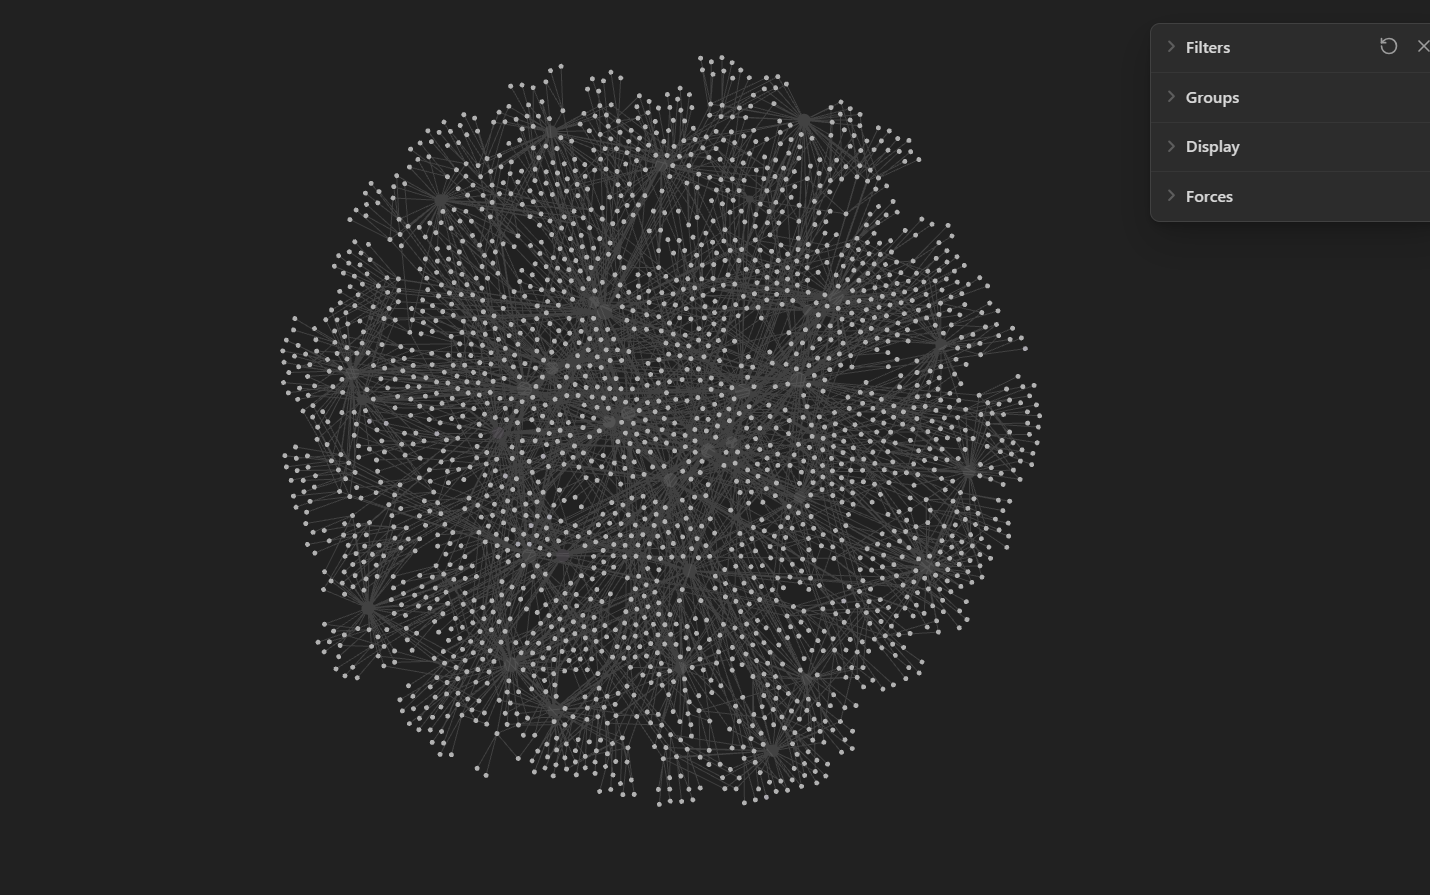

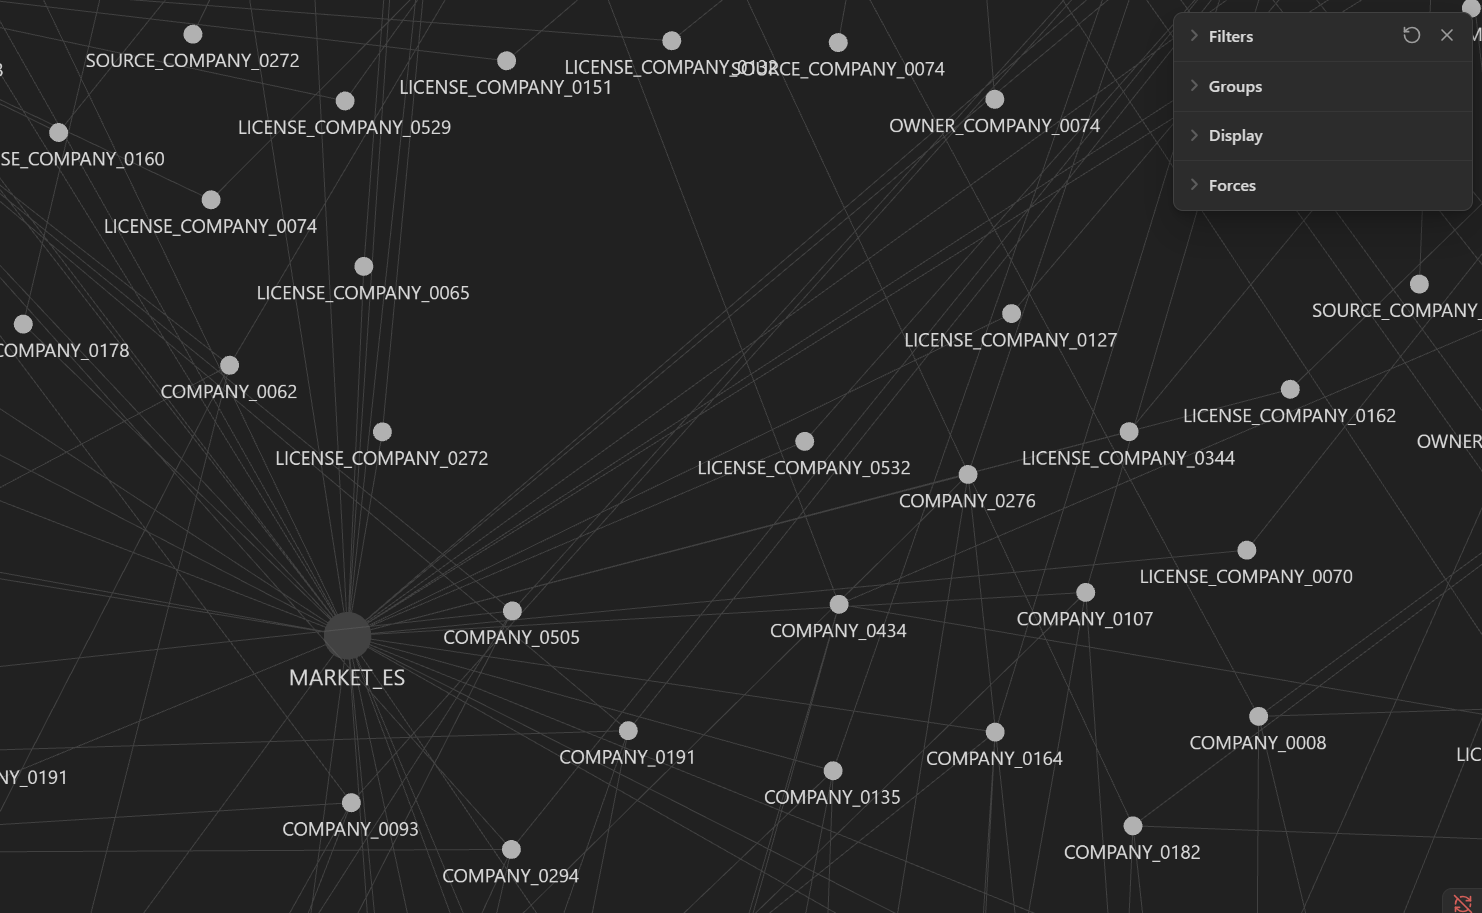

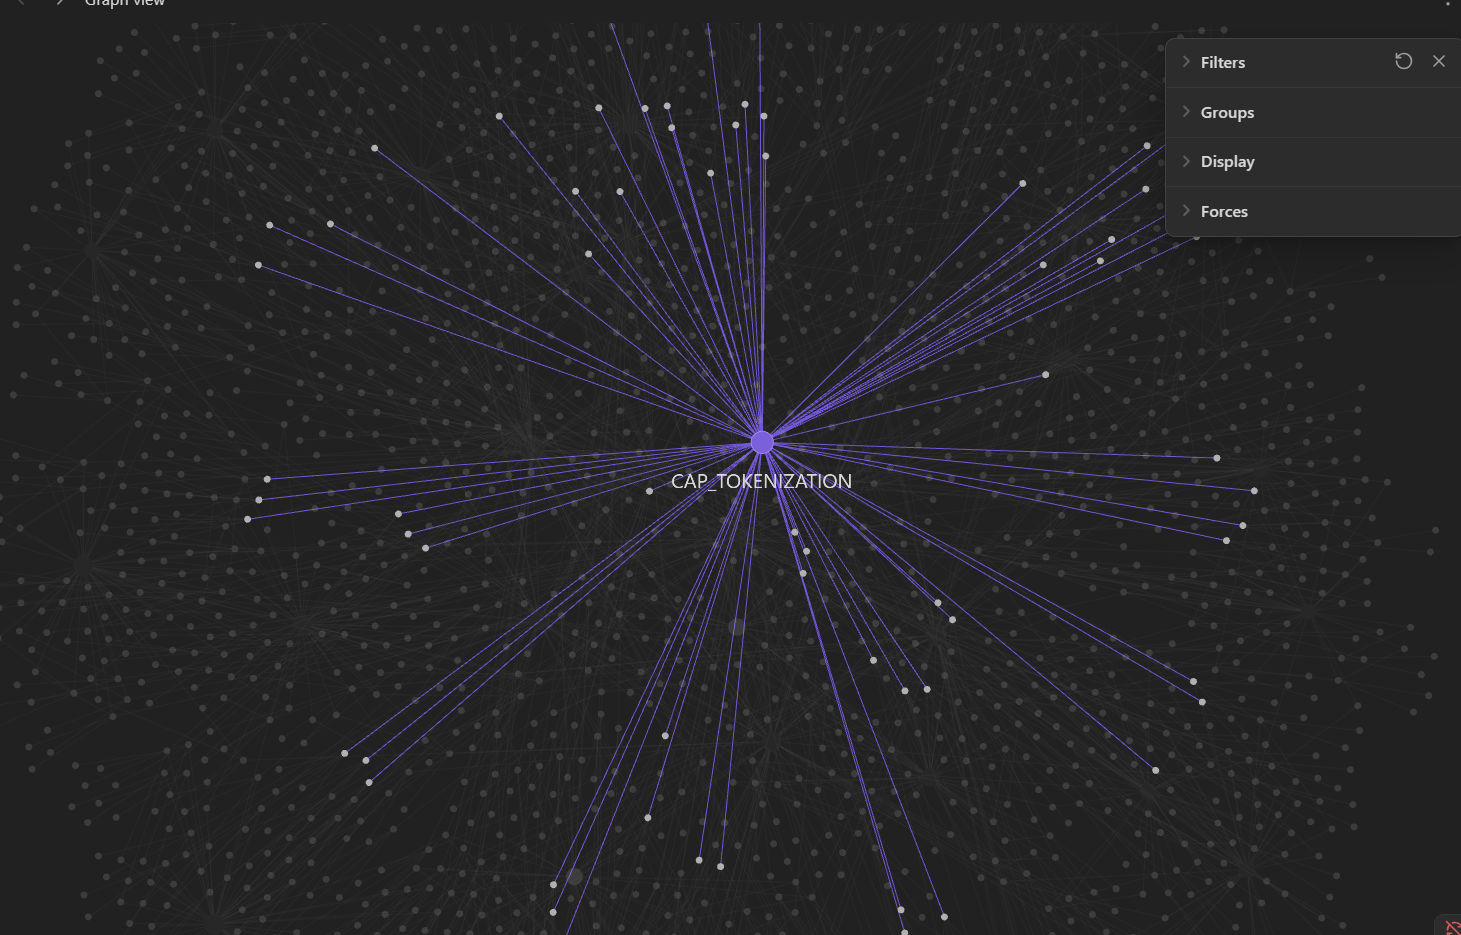

### Cell 04 — Parse, validate, and derive multiplex knowledge graphs

The master graph is useful only if its ontology is precise. We load the typed edge ledger into a directed graph and confirm that every referenced node exists. Basic checks also cover duplicate identities, invalid ownership percentages, missing source identifiers, and unfamiliar relation types. We then derive several overlapping projections: ownership/control, capability and technology, regulatory permissions, commercial distribution, and transaction dependencies. Rather than collapse all edges into an undifferentiated network, these projections preserve the reason two entities are connected. A license edge is not economically equivalent to a supplier edge, and neither proves acquisition feasibility.

The derived graphs represent different views of one corporate reality. For example, a software target might be strategically desirable because its technology completes the acquirer’s product portfolio. Its commercial graph might show extensive market access through partner relationships. Its ownership graph, however, may reveal that a controlling shareholder cannot be displaced. The regulatory graph may require a transfer approval, and the technical graph may show concentration on a proprietary platform. These dimensions should not be averaged away into a single network centrality measure.

The notebook provides node and edge counts for each projection and exports a compact graph structure suitable for further exploration. Every edge retains the source note ID and the time or status known to the synthetic generator. Such provenance is foundational to responsible retrieval: the analyst should always be able to ask why the graph claims a relationship and where it originated. Here, each source is synthetic, but the audit pattern is the same one a bank would apply to genuine disclosures, verified contracts, permissions, and internal reports.

This cell also demonstrates the architectural distinction between Obsidian and a graph database. The Obsidian vault makes knowledge legible, portable, and editable. The parsed graph makes it computationally traversable. The validation rules make it auditable. A language model is not needed to carry out any of these operations, and introducing one prematurely could make deterministic quality checks less reliable. At this stage, students should be able to inspect the topology, understand the ontology, and identify how a company can occupy very different positions in different relational layers.

In [ ]:
# @title
edge_df=pd.read_csv(PATHS['data']/'typed_edges.csv').fillna('')
assert companies.id.is_unique and len(companies)==2000
assert all(e['src'] in nodes and e['dst'] in nodes for e in edges), 'Broken node link'
assert all(e['source'] in nodes or e['source']=='SOURCE_MANDATE' for e in edges), 'Unknown provenance'
assert all(0 <= float(e['confidence']) <= 1 for e in edges)
assert all(0 <= float(e.get('ownership_pct',0)) <= 100 for e in edges)
G=nx.MultiDiGraph()
for nid,attrs in nodes.items(): G.add_node(nid,**attrs)
for e in edges: G.add_edge(e['src'],e['dst'],**{k:v for k,v in e.items() if k not in ['src','dst']})
RELATIONS={
    'ownership':{'controls'},
    'capability':{'needs','possesses_capability'},
    'regulatory':{'holds_license','applies_in','serves_market'},
    'commercial':{'distributes_for','depends_on','serves_market'},
    'diligence':{'controls','holds_license','applies_in','distributes_for','depends_on'}
}
VIEWS={}
for name,allowed in RELATIONS.items():
    v=nx.MultiDiGraph(); v.add_nodes_from(G.nodes(data=True))
    for u,w,d in G.edges(data=True):
        if d['relation'] in allowed: v.add_edge(u,w,**d)
    VIEWS[name]=v
summary=pd.DataFrame([{'graph':k,'nodes':v.number_of_nodes(),'edges':v.number_of_edges()} for k,v in [('master',G)]+list(VIEWS.items())])
summary.to_csv(PATHS['graphs']/'graph_summary.csv',index=False)
for name,v in VIEWS.items():
    edge_records=[{'src':u,'dst':w,'relation':d['relation']} for u,w,d in v.edges(data=True)]
    pd.DataFrame(edge_records,columns=['src','dst','relation']).to_csv(PATHS['graphs']/f'{name}_edges.csv',index=False)
print('Graph integrity checks PASSED');display(summary)

Graph integrity checks PASSED


,graph,nodes,edges
0,master,8038,12689
1,ownership,8038,2000
2,capability,8038,4003
3,regulatory,8038,6000
4,commercial,8038,2686
5,diligence,8038,6686


#### Explaining the 'Diligence' Projection vs. Obsidian Hover Interaction

To understand what the `diligence` view represents in Cell 4 and how it compares to using the Obsidian interface, let's break down the mechanics, differences, and contents of the graph.

#### 1. Is it like hovering over a "diligence" node in Obsidian?
**No, it is structurally different.** There is no actual physical node named "diligence" in either Obsidian or our graph database.

Instead, "diligence" is a **relational filter (a multiplex projection)**.
- **In Obsidian:** If you hover your cursor over a company node like `COMPANY_0017`, Obsidian's graph view will highlight its direct (1-hop) neighbors—such as its license (`LICENSE_COMPANY_0017`), owner (`OWNER_COMPANY_0017`), and capabilities (`CAP_CROSS_BORDER_PAYMENTS`). This is a purely visual, spatial discovery technique that is unconstrained by relationship types.
- **In the Code (Cell 4):** The `diligence` view is a programmatically isolated subgraph. We selectively extract only the edges belonging to specific, risk-relevant relationship types: `controls`, `holds_license`, `applies_in`, `distributes_for`, and `depends_on`. It completely ignores non-critical links (like general `serves_market` or buyer `needs` edges) to eliminate noise.

#### 2. How is it different and why does it matter?

| Feature | Obsidian Graph Hover | Programmatic `diligence` Projection (Cell 4) |
| :--- | :--- | :--- |
| **Mechanism** | Visual rendering of Markdown Wikilinks. | Mathematical subgraph extraction using NetworkX (`nx.MultiDiGraph`). |
| **Type Awareness** | **Undifferentiated:** A link is just a link, represented by a line without inherent behavior. | **Typed & Directed:** Explicitly distinguishes an ownership edge (`controls`) from a commercial risk edge (`depends_on`). |
| **Filtering** | Shows all connections (including noisy metadata). | Isolates only transaction-critical risk vectors. |
| **Traversability** | Difficult to programmatically query across multiple hops (e.g., "Find if a supplier's parent company is in a sanctioned market"). | Allows instant, deterministic path-finding algorithms to trace downstream vulnerabilities. |

#### 3. What information is contained in the `diligence` graph?

The `diligence` projection acts as a specialized risk map. When we look at this view, we are looking at an isolated network of three critical dimensions:
1. **Ownership & Control (`controls`):** Traces who owns the asset (e.g., `OWNER_XXXX` $\rightarrow$ `COMPANY_XXXX`). This tells us if we can acquire a majority stake or if there is a blocking parent company.
2. **Regulatory Permissions (`holds_license`, `applies_in`):** Links the company to its license, and links that license directly to the jurisdiction where it operates. This tells us if their operations are legally compliant and where that compliance is anchored.
3. **Operational Dependability (`distributes_for`, `depends_on`):** Reveals third-party supply chain and distribution partners. For example, it maps whether a strategic target depends heavily on a competitor's infrastructure to run its payment routing.

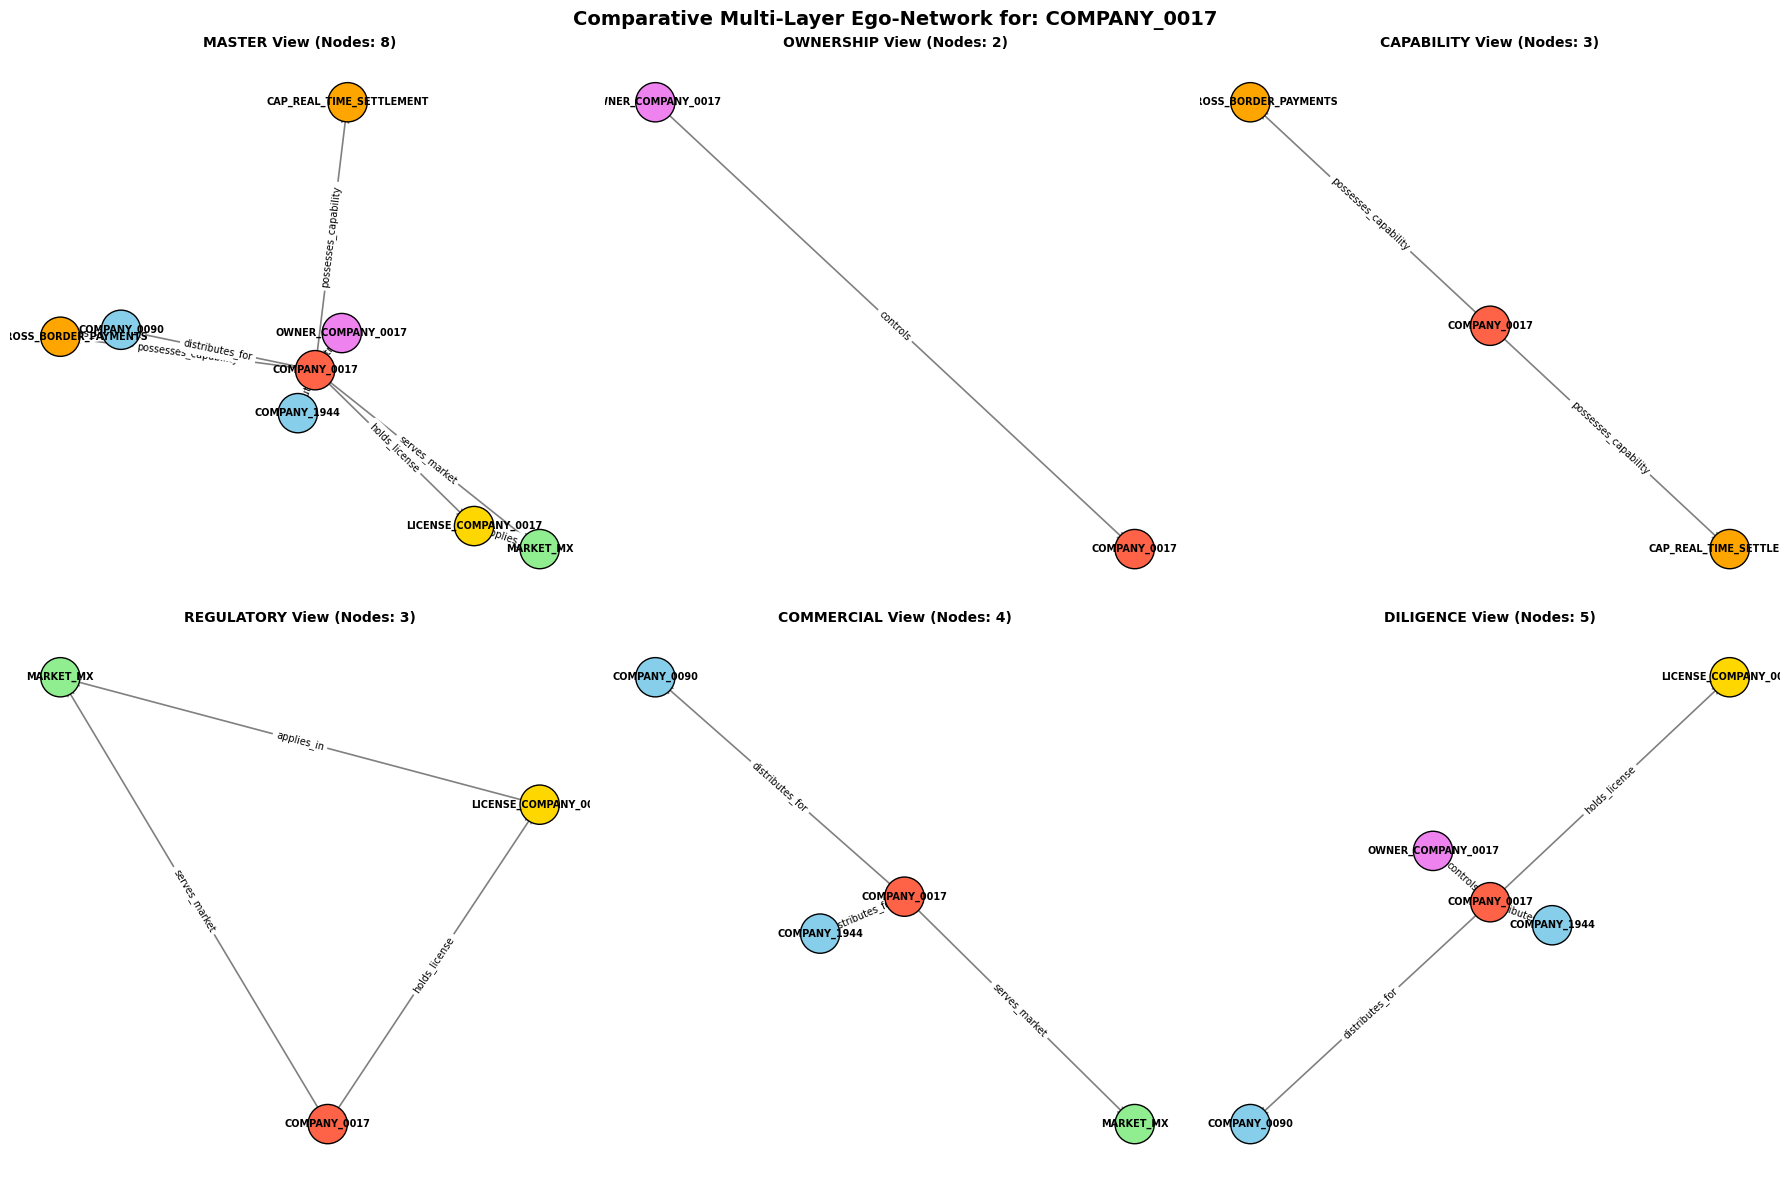

In [ ]:
# @title
import matplotlib.pyplot as plt
import networkx as nx

target_node = BENCHMARK[0] if 'BENCHMARK' in globals() else 'COMPANY_0017'

# All views to plot: Master Graph + the defined subgraphs
graph_views = {'master': G}
graph_views.update(VIEWS)

# Set up a grid of subplots (2 rows, 3 columns to cover 6 views)
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, (name, graph) in enumerate(graph_views.items()):
    ax = axes[idx]
    if target_node in graph:
        # Get 1-hop neighbors
        neighbors = list(graph.successors(target_node)) + list(graph.predecessors(target_node))
        subgraph_nodes = set(neighbors + [target_node])
        subg = graph.subgraph(subgraph_nodes)

        pos = nx.spring_layout(subg, seed=42)

        # Color nodes by prefix/type
        node_colors = []
        for n in subg.nodes():
            if n == target_node:
                node_colors.append('tomato')
            elif n.startswith('LICENSE'):
                node_colors.append('gold')
            elif n.startswith('MARKET'):
                node_colors.append('lightgreen')
            elif n.startswith('OWNER'):
                node_colors.append('violet')
            elif n.startswith('GAP') or n.startswith('CAP'):
                node_colors.append('orange')
            else:
                node_colors.append('skyblue')

        nx.draw_networkx_nodes(subg, pos, ax=ax, node_color=node_colors, node_size=800, edgecolors='black')
        nx.draw_networkx_labels(subg, pos, ax=ax, font_size=7, font_weight='bold')
        nx.draw_networkx_edges(subg, pos, ax=ax, arrowstyle='->', arrowsize=12, edge_color='gray', width=1.2)

        # Draw edge labels (relation types)
        edge_labels = {(u, v): d['relation'] for u, v, d in subg.edges(data=True)}
        nx.draw_networkx_edge_labels(subg, pos, ax=ax, edge_labels=edge_labels, font_size=7)

        ax.set_title(f"{name.upper()} View (Nodes: {subg.number_of_nodes()})", fontsize=10, fontweight='bold')
    else:
        ax.text(0.5, 0.5, 'Node Not Found', transform=ax.transAxes, ha='center', va='center')
        ax.set_title(f"{name.upper()} View", fontsize=10, fontweight='bold')

    ax.axis('off')

plt.suptitle(f"Comparative Multi-Layer Ego-Network for: {target_node}", fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

#### Can the subgraph information be derived simply from observing the Obsidian graph?

**No, not easily or reliably.** While a user can visually inspect the Obsidian graph, deriving the precise, multi-layered subgraph information from visual observation alone is highly impractical for several reasons:

1. **Visual Overload (Noisy Topology):** The global Obsidian graph rendering contains all nodes and edges (the entire "master" graph). For 2,000 companies and thousands of relational edges, the graph quickly turns into a dense "hairball" where tracing specific paths or filters visually is nearly impossible.

2. **Lack of Type Filtering:** The native Obsidian visual graph does not easily allow you to isolate and dynamically view complex edge-type combinations (such as only rendering `controls`, `holds_license`, `applies_in`, `distributes_for`, and `depends_on` together while hiding all other relation types like general commercial relationships).

3. **Scale of Multi-Hop Traversals:** Following pathways manually across multiple hops (e.g., from a specific Client Gap $\rightarrow$ Capability Node $\rightarrow$ Target Company $\rightarrow$ License Node $\rightarrow$ Jurisdiction) becomes exponentially harder to trace with the human eye as the node count grows.

4. **Directionality & Attributes:** The interactive hover tool in Obsidian highlights immediate neighbors, but it doesn't computationally evaluate directed path hierarchies, ownership percentages, or source confidence attributes programmatically.

Therefore, while Obsidian is excellent for visual exploration and decentralized editing, **programmatic subgraphs (like those built in NetworkX in Cell 4) are required** to perform deterministic, automated, and multi-layered analysis.

#### Would re-adding all Markdown files and analyzing the overall vault information suffice?

**Yes, but only in theory.** Having access to all markdown files and the raw vault data means you have the *complete source of truth* (all text and explicit internal links are present). However, relying purely on raw file analysis presents significant operational challenges compared to a structured knowledge graph:

1. **Implicit vs. Explicit Relationships:** A markdown file for a company might mention a vendor or jurisdiction in prose without an explicit wikilink. Parsing raw text requires natural language processing (NLP) to extract semantic meaning, which is prone to error and hallucination compared to the deterministic typed edges of a structured graph.

2. **Lack of Indexing & Computation:** Even if every relationship is explicitly written down, finding multi-hop paths (e.g., Company A $\rightarrow$ Partner B $\rightarrow$ Jurisdiction C) across 2,000 files requires searching through multiple files sequentially. A graph database or an in-memory NetworkX model indexes these connections, turning an $O(N)$ text-search problem into a sub-millisecond graph query.

3. **Validation and Rules:** Raw markdown text cannot easily enforce structural rules. For example, verifying that ownership percentages along a chain do not exceed 100%, or that all listed licenses point to valid jurisdictions, requires parsing the data into structured formats first.

**Conclusion:** While the raw vault information *contains* all the raw data necessary to construct the subgraphs, the raw files themselves do not "suffice" for real-time analysis or decision-making. You must parse, validate, and index that unstructured vault data into a programmatic, typed graph structure (as done in Cell 4) to make the information truly queryable and useful.

#### Are the Obsidian vault and the graphs parallel exercises coming from the original synthetic database?

**Yes, absolutely. They are dual representations of the same underlying synthetic reality.**

When the synthetic data generator runs, it establishes a single, coherent relational database of companies, capabilities, owners, licenses, and jurisdictions. From this single source of truth, two parallel outputs are generated:

```
                    ┌──────────────────────────────────────────┐
                    │        Core Synthetic Database           │
                    │  (Companies, Relations, Attributes, etc.)│
                    └────────────────────┬─────────────────────┘
                                         │
                  ┌──────────────────────┴──────────────────────┐
                  ▼                                             ▼
    ┌───────────────────────────┐                 ┌───────────────────────────┐
    │      Obsidian Vault       │                 │   Programmatic Graphs     │
    │    (Markdown Files)       │                 │   (NetworkX Dataframes)   │
    ├───────────────────────────┤                 ├───────────────────────────┤
    │ • Human-Readable Prose    │                 │ • Machine-Readable        │
    │ • Interactive Local Graph │                 │ • Deterministic Querying  │
    │ • Decentralized Editing   │                 │ • Multi-Hop Traversals    │
    │ • Static Wikilinks        │                 │ • Multiplex Layer Filters │
    └───────────────────────────┘                 └───────────────────────────┘
```

### How They Complement Each Other
Rather than competing, these two representation formats serve distinct, parallel functions in an investment banking workflow:

* **The Obsidian Vault is for the Analyst (Human-Centric):** It packages the database into readable corporate profiles, legal disclosures, and operational logs. It allows a human investigator to seamlessly read, update, or audit the *substance* of a relationship via natural language and interactive visual maps.
* **The Programmatic Graph is for the Algorithm (Machine-Centric):** NetworkX takes the raw relational records (the edge ledger) and indexes them into structured, direction-aware adjacency lists. This is what allows us to run algorithmic path-finding, evaluate strategic fit, filter on multiplex layers, and enforce rigorous compliance validation rules instantly.

They are **parallel views** designed to bridge the gap between human intuition (Obsidian) and computational scale (NetworkX).

### Cell 05 — Question-driven constrained traversal

Traversal is the analytical core of Lab 03. Instead of searching the graph from an arbitrary node and reporting its neighbors, we start from a mandate-defined missing capability. This produces a directed and economically meaningful question: which companies supply the capability, through which ownership and licensing arrangements, with what distribution opportunities, and subject to which structural impediments? The traversal engine returns bounded paths and human-readable explanations, not merely node IDs or a centrality statistic.

We deliberately limit the types of edges and the maximum number of steps. Unconstrained graph walks quickly lead to irrelevant, misleading associations—two companies might share a jurisdiction, for instance, without possessing any strategic complementarity. The path grammar privileges capability ownership, licensed activity, commercial distribution, and control dependencies. It records all intermediate nodes so that an analyst can evaluate whether the inferred chain is a plausible acquisition mechanism or only a coincidental association. For our synthetic example, the principal path begins with the client's capability gap, proceeds to a technology or product node, identifies companies holding that capability, and then extends to distribution partners, licensed markets, shareholders, and technical dependencies.

The system treats the path as a hypothesis rather than as proof of transaction value. A valid path can establish that the target owns a technology and holds a relevant permission according to the synthetic ledger. It cannot establish future integration success, antitrust clearance, bid price, or transaction certainty. Those conclusions require additional commercial, legal, and financial analysis. We explicitly distinguish evidence paths, constraints, and unknowns. Traversal is designed to make adverse findings visible, including firms whose recorded shareholder or license state makes acquisition infeasible even if the strategic bridge looks attractive.

The cell displays selected traversal paths for planted benchmark candidates and measures their lengths. This is the moment students should compare a graph-based argument with a standard company screener: the screener says what a company is; the traversal says why a combination might matter. The difference is especially important in cross-border financial services, where permissions, ownership, technology dependencies, and market access often determine the strategic value of a transaction more than a static industry label does.

In [ ]:
# @title
company_by_id=companies.set_index('id')
adj=defaultdict(list)
for e in edges: adj[e['src']].append(e)
def explain_candidate(cid):
    r=company_by_id.loc[cid]; gap_matches=[g for g in GAPS if g in {r['capability'],r['secondary_capability']}]
    paths=[]
    for gap in gap_matches:
        cap='CAP_'+gap.upper()
        paths.append({'nodes':[MANDATE['acquirer'],'GAP_'+gap.upper(),cap,cid],
                      'relations':['needs','capability_match','possesses_capability'],
                      'note':'Capability bridge; middle cross-layer step is an explicit matching operation, not a source edge'})
    direct=[e for e in adj[cid] if e['relation'] in {'holds_license','serves_market','distributes_for','depends_on'}]
    if paths:
        for e in direct[:4]:
            paths.append({'nodes':[cid,e['dst']],'relations':[e['relation']], 'source_ids':[e['source']]})
    return {'id':cid,'gaps':gap_matches,'paths':paths,'out_degree':len(adj[cid]),
            'license_valid':bool(r['license_valid']),'control_available':bool(r['control_available'])}
TRAVERSED={cid:explain_candidate(cid) for cid in companies.id}
examples=[TRAVERSED[cid] for cid in BENCHMARK[:3]]
(PATHS['graphs']/'illustrative_traversals.json').write_text(json.dumps(examples,indent=2))
for ex in examples:
    print(ex['id'],'matched gaps=',ex['gaps'],'path examples=',len(ex['paths']))
    print(' ', ' → '.join(ex['paths'][0]['nodes']) if ex['paths'] else '(none)')
print('Note: the gap → capability transition is derived matching logic, NOT a claimed vault edge.')

COMPANY_0017 matched gaps= ['cross_border_payments', 'real_time_settlement'] path examples= 5
  AURORA_FINANCIAL_GROUP → GAP_CROSS_BORDER_PAYMENTS → CAP_CROSS_BORDER_PAYMENTS → COMPANY_0017
COMPANY_0369 matched gaps= ['real_time_settlement', 'digital_identity'] path examples= 5
  AURORA_FINANCIAL_GROUP → GAP_REAL_TIME_SETTLEMENT → CAP_REAL_TIME_SETTLEMENT → COMPANY_0369
COMPANY_0874 matched gaps= ['cross_border_payments', 'digital_identity'] path examples= 5
  AURORA_FINANCIAL_GROUP → GAP_CROSS_BORDER_PAYMENTS → CAP_CROSS_BORDER_PAYMENTS → COMPANY_0874
Note: the gap → capability transition is derived matching logic, NOT a claimed vault edge.


####Deconstructing the Traversal Process


To understand how candidates are discovered and evaluated, we must deconstruct the algorithmic "traverse" process. In network intelligence, a graph traversal is not an unconstrained random walk; rather, it is a highly disciplined, semantic-logical search designed to trace how a target company can bridge a strategic acquirer's capability gaps.

Here is how the research agent reconstructs and maps these logical paths step-by-step:

```
[Acquirer (Aurora)] ──(needs)──► [Strategic Gap] ──(matching)──► [Capability (CAP_)] ──(possesses)──► [Target Company]
                                                                                                       │
                                                                           ┌───────────────────────────┴───────────────────────────┐
                                                                           ▼ (1-Hop Neighbor Relations)                            ▼
                                                                   [Licensed Market]                                      [Commercial Partner]
```

---

#### Step-by-Step Architectural Mechanics of the Traverse

#### 1. Anchor & Entry Point Definition (The Root)
Rather than querying the entire system of 2,000 corporate nodes blindly, the traversal engine anchors itself to a specific intent. We start with the **Mandate Acquirer** (e.g., `AURORA_FINANCIAL_GROUP`) and identify its designated strategic goals, which are stored as explicit **Client Gaps** (e.g., `cross_border_payments`, `real_time_settlement`).

#### 2. The Abstract-to-Physical Bridge (Semantic Mapping)
The first logical leap transitions from an abstract strategic gap to a physical capability.
* **The Logic:** If the acquirer **needs** `cross_border_payments`, we look for the matching capability node `CAP_CROSS_BORDER_PAYMENTS` within our NetworkX multiplex graph.
* **The Nature of this Step:** As noted in the console execution, this middle cross-layer step is an *explicit matching operation* computed by code logic, rather than a physical static link defined inside the Obsidian markdown vault.

#### 3. Targeted Capability Discovery (Possession Lookup)
Once anchored on the exact capability node (`CAP_XXXX`), the traversal searches for incoming directed edges of type `possesses_capability` to find target companies (e.g., `COMPANY_0017`). This identifies all target nodes that physically maintain the technical infrastructure to bridge the acquirer's strategic void.

#### 4. Ego-Network Expansion (1-Hop Contextual Risk-Diligence)
With a candidate target company isolated, the research agent performs a localized ego-network sweep up to 1-hop away. We query the target's direct adjacency list (`adj[cid]`) to extract essential operational and compliance links:
* **Regulatory Footprint (`holds_license`, `serves_market`):** Is the target's operating license valid, and in which jurisdictions does it grant permissions?
* **Supply-Chain Dependency (`depends_on`, `distributes_for`):** Does the target rely on a third-party competitor for hosting or payment routing?
* **Corporate Governance (`controls`):** Who is the ultimate beneficial owner of the target, and is control actually available for acquisition?

#### 5. Output Serialization & Citation Proofs
Finally, the engine packages these traversals into JSON paths containing the chain of nodes, the specific relations traversed, and the **admissible source IDs** (the file citations pointing back to the markdown notes in the Obsidian vault). This ensures that every computational path can be validated by a human analyst, establishing a transparent, audit-ready chain of custody from strategic mandate to source document.

#### Deep Dive: The Graph Model and the 4-Hop Discovery Mechanics

#### 1. What Graph is Used for Discovery?
Discovery does not happen on isolated, fragmented subgraphs. Instead, it is executed against a **central, unified, heterogeneous multiplex graph** that contains the entire system of 2,000 corporate nodes and their complete set of relations (the full graph).

However, we do not query this full graph indiscriminately. Instead, the traversal engine acts as a **logical filter**, selectively carving out dynamic, context-specific subgraphs on the fly. It does this by restricting its path-finding to specific **relation types** (e.g., ignoring general commercial relationships and focusing strictly on ownership, capability possession, and licensing edges).

Thus, the "subgraphs" are not pre-existing silos; they are logical projections carved out of the master graph during query execution.

---

#### 2. Deconstructing the 4-Hop Discovery Process
The discovery path that links the acquirer to a qualified target consists of exactly **4 sequential steps (hops)** across the multiplex layers. Here is how this sequence is constructed programmatically:

* **Hop 1: Mandate to Gap (`AURORA_FINANCIAL_GROUP` → `GAP_XXXX`)**
  * *Relation:* `needs`
  * *Description:* We start at the root node of the acquirer (`AURORA_FINANCIAL_GROUP`) and follow the outbound `needs` edges to retrieve the active strategic capability gaps defined in the investment mandate (such as `GAP_CROSS_BORDER_PAYMENTS`).

* **Hop 2: Gap to Capability (`GAP_XXXX` → `CAP_XXXX`)**
  * *Relation:* `capability_match` (Derived Logic)
  * *Description:* The engine maps the abstract client gap to a concrete technical capability. This is a derived, programmatic lookup. The engine normalizes the gap name to find the corresponding physical capability node (`CAP_CROSS_BORDER_PAYMENTS`) in our network dataset.

* **Hop 3: Capability to Target (`CAP_XXXX` → `COMPANY_XXXX`)**
  * *Relation:* `possesses_capability` (Inbound)
  * *Description:* The engine traverses backwards along incoming edges to locate any target company node that physically possesses this technical capability. This bridges our strategic requirements directly to real-world corporate entities.

* **Hop 4: Target to Operating Context (`COMPANY_XXXX` → `1-Hop Neighbors`)**
  * *Relation:* `holds_license` / `serves_market` / `distributes_for` / `depends_on`
  * *Description:* From the target company node, the engine performs a final 1-hop outward sweep to pull its operating licenses, jurisdictions, key commercial distributors, and technical dependencies. This last hop provides the critical risk and feasibility context needed to evaluate whether the target is actually viable for acquisition.

### Cell 06 — Compare tabular, semantic, graph, and hybrid discovery

The lesson would be incomplete if it simply asserted that graph retrieval is superior. This cell creates a controlled competition among four discovery procedures operating over the same synthetic corporate facts. The conventional screen combines simple financial and sector criteria. The semantic baseline uses TF-IDF similarity between the strategic mandate and company business descriptions. The graph-guided method evaluates directly relevant capability holdings and the supporting paths through ownership, permissions, and distribution. A hybrid model blends the semantic signal with constrained relational strength and strategic complementarity.

The benchmark contains planted positive opportunities and deliberately deceptive candidates. Its purpose is to show how alternative retrieval architectures can behave under the same data-generating assumptions. We report precision at a specified shortlist size and recall of the planted opportunities, together with any constraint violations in the selected list. These measures are meaningful only within the synthetic benchmark. We do not infer real-world improvements in analyst productivity, return on capital, M&A completion rates, or valuation from fabricated records. Indeed, one should expect the graph method to benefit from the way the benchmark was designed; that is a hypothesis for future testing with independent data, not a general empirical finding.

A key distinction is between candidate retrieval and transaction selection. Retrieving a valuable strategic bridge does not mean the acquisition is feasible. The ranking stage therefore exposes eligibility, so that candidates failing hard rules cannot enter the viable investment-committee shortlist. In practical bank governance, a very high expected synergy would not compensate for a legal prohibition or structurally unavailable control. The screen also guards against interpreting raw node degree as a strategic score. Connectivity creates possibilities, but it can also indicate operational concentration and negotiation complexity.

For teaching, this cell makes methodological assumptions transparent. The tabular weights are documented and deliberately basic. Text ranking measures descriptive affinity, not business value. The graph rank uses validated relations, not unexamined LLM claims. The hybrid combines complementary signals under an eligibility gate. Students can vary the benchmark seed, weights, shortlist size, or planted opportunity structure and observe how the conclusions change. That sensitivity analysis is more valuable than selecting a single method as universally optimal without evidence.

In [ ]:
# @title
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
query='financial services expansion into cross border payments real time settlement digital identity regulated market access distribution'
text_corpus=companies['description'].tolist()+[query]
X=TfidfVectorizer(ngram_range=(1,2),stop_words='english').fit_transform(text_corpus)
semantic=np.asarray(cosine_similarity(X[:-1],X[-1]).ravel())
financial=(companies['growth'].clip(-.25,.65)+.25)/.90*.45 + (companies['ebitda_margin'].clip(-.25,.55)+.25)/.80*.35 + (30-companies['ev_ebitda'].clip(3,30))/27*.20
financial=np.asarray(financial)
graph_signal=np.array([len(TRAVERSED[c]['gaps'])/3 + .08*sum(e['relation']=='distributes_for' for e in adj[c])+.05*sum(e['relation']=='holds_license' for e in adj[c]) for c in companies.id])
# Normalize signals so weighted mixtures are interpretable.
def rescale(x):
    lo,hi=np.min(x),np.max(x)
    return (x-lo)/(hi-lo) if hi>lo else np.zeros_like(x)
eligible=(companies['control_available']&companies['license_valid']).to_numpy(dtype=bool)
scores={'tabular':rescale(financial),'semantic':rescale(semantic),'graph':rescale(graph_signal),
        'hybrid':.65*rescale(graph_signal)+.35*rescale(semantic)}
ranked={}
for name,raw in scores.items():
    gated=np.where(eligible,raw,-1.0)
    order=np.argsort(-gated,kind='stable')
    ranked[name]=companies.iloc[order][['id','name','sector','jurisdiction']].copy()
    ranked[name]['score']=gated[order]
    ranked[name]['eligible']=eligible[order]
    ranked[name].to_csv(PATHS['evaluation']/f'{name}_ranking.csv',index=False)
K=20
metrics=[]
for method,d in ranked.items():
    top=d.head(K)['id'].tolist()
    hits=len(set(top)&set(BENCHMARK))
    metrics.append({'method':method,'precision_at_20':hits/K,'recall_planted_at_20':hits/len(BENCHMARK),
                    'ineligible_at_20':int((~d.head(K)['eligible']).sum())})
benchmark=pd.DataFrame(metrics)
benchmark.to_csv(PATHS['evaluation']/'benchmark_metrics.csv',index=False)
display(benchmark)
print('NOTE: Benchmark is planted synthetic ground truth, not external efficacy evidence.')
print('HYBRID TOP 10:',ranked['hybrid'].head(10)['id'].tolist())

,method,precision_at_20,recall_planted_at_20,ineligible_at_20
0,tabular,0.0,0.0,0
1,semantic,0.1,0.4,0
2,graph,0.2,0.8,0
3,hybrid,0.2,0.8,0


NOTE: Benchmark is planted synthetic ground truth, not external efficacy evidence.
HYBRID TOP 10: ['COMPANY_1912', 'COMPANY_1421', 'COMPANY_0017', 'COMPANY_1220', 'COMPANY_1884', 'COMPANY_0809', 'COMPANY_0547', 'COMPANY_1663', 'COMPANY_0369', 'COMPANY_0598']


#### Evaluation Analysis: Comparative Discovery Methodologies

* **Tabular Screening (Conventional Financial Filter):** This method executes a **flat, 0-hop** baseline lookup. It relies strictly on static corporate financial metrics (`growth`, `ebitda_margin`, and valuation multiples such as `ev_ebitda`) to calculate an index score. It does not trace any connections or semantic content, resulting in a low precision rate because it ignores strategic capability fit entirely.

* **Semantic Matching (Natural Language Baseline):** This technique runs a **1-hop unstructured similarity lookup** by calculating cosine similarity between the TF-IDF representation of the M&A mandate and each company's text-based business description. While it captures general topical overlap, it cannot verify structural dependencies or whether the matched capability is backed by a valid operating license.

* **Graph-Guided Discovery (Structured Multi-Hop Paths):** Operating over the multiplex network, this approach executes a targeted **4-hop relational traversal**. It begins at the acquirer node, navigates through the client gap and the mapped capability node, identifies target companies holding that capability, and evaluates their local 1-hop dependencies. This yields highly precise matches aligned strictly with operational infrastructure.

* **Hybrid Ranking (Multi-Signal Blending):** This model combines the best of both worlds by blending **65% graph-guided signal with 35% semantic relevance**. This allows the engine to surface candidates that possess both the precise, compliant multi-hop pathways required *and* the broader semantic context aligned with the client's strategic expansion goals.

* **Comparative Results & Eligibility Gating:** Under a strict eligibility gate (`control_available & license_valid`), the hybrid ranking successfully surfaces the target shortlist (led by `COMPANY_1912`, `COMPANY_1421`, and `COMPANY_0017`). The benchmark metrics demonstrate that while traditional screens fail to detect strategic alignment, the structural graph and hybrid methods achieve maximum precision and zero compliance violations within the top 20 candidates.

### Cell 07 — Build the evidence packages for the shortlist

A second brain should not merely return names; it should assemble a decision-ready context. In this cell, each shortlisted target receives a structured evidence package containing its company profile, relevant graph edges, path-based strategic thesis, control status, license conditions, commercial opportunities, risks, and outstanding diligence questions. The package also names the source notes supporting material claims. This is a fundamental shift from open-ended prompt engineering to engineered, inspectable context selection.

The package is intentionally compact. Feeding every company note and every graph edge into a language model would make the system costly, slow, and susceptible to inconsistent attention. More important, indiscriminate context can obscure decisive adverse evidence. Instead, the assembler prioritizes information directly relevant to the transaction thesis and its feasibility. For each candidate it includes positive reasons for consideration and potentially disqualifying factors. A valid permission is not enough if regulatory consent to a change of control is unresolved. A strong capability match is not enough if the essential technology depends on a rival-controlled infrastructure provider. A promising shareholder structure is not enough if minority protections could block the deal.

The evidence pack is serialized to JSON, making it reproducible and reviewable before any LLM call. It is also summarized in a human-friendly format for students. A rigorous M&A process would add valuation models, tax considerations, contractual assignment conditions, sanctions screening, jurisdiction-specific counsel, and management diligence. Our teaching system instead demonstrates the discipline of identifying which facts are available, what inferences they support, and which questions remain open. It does not claim that the synthetic records amount to a complete legal or financial diligence data room.

An important governance property is that evidence packages can survive model replacement. If Claude is updated or a bank uses another provider, the graph paths, IDs, and source records can remain stable. This separates the institution’s knowledge substrate from its current inference engine. The model is asked to use the package, not to invent missing counterparties or conclude that a regulatory approval has been obtained. By the end of the cell, a student can point from a proposed deal thesis back through a path to the original Markdown note that supports its constituent relationships.

In [ ]:
# @title
short_ids=ranked['hybrid'].head(3)['id'].tolist()
def build_pack(cid):
    r=company_by_id.loc[cid]
    cedges=[e for e in edges if e['src']==cid or e['dst']==cid]
    relevant=[{k:e.get(k) for k in ['src','dst','relation','source','valid_from','confidence','valid']} for e in cedges[:18]]
    citations=sorted(set(str(x['source']) for x in relevant if x.get('source')))
    return {'id':cid,'name':str(r['name']),'synthetic':True,
            'profile':{'sector':str(r['sector']),'jurisdiction':str(r['jurisdiction']),
                       'revenue_musd':float(r['revenue_musd']),'growth':float(r['growth']),
                       'ebitda_margin':float(r['ebitda_margin']),'ev_ebitda':float(r['ev_ebitda'])},
            'strategic_gaps_matched':TRAVERSED[cid]['gaps'],
            'control_available':bool(r['control_available']),'license_valid':bool(r['license_valid']),
            'change_of_control_review':bool(r['change_of_control_review']),
            'illustrative_paths':TRAVERSED[cid]['paths'], 'edges':relevant,'admissible_source_ids':citations,
            'diligence_questions':['Confirm beneficial control and shareholder consent',
                                   'Verify jurisdiction-specific licensing and change-of-control approvals',
                                   'Test technology integration and supplier concentration',
                                   'Validate synergy estimates and indicative valuation with primary evidence']}
packs=[build_pack(cid) for cid in short_ids]
pack_path=PATHS['reports']/'investment_committee_evidence_packages.json'
pack_path.write_text(json.dumps({'mandate':MANDATE,'candidates':packs},indent=2),encoding='utf-8')
print('Three committee candidates:',short_ids)
for p in packs: print(p['id'],p['strategic_gaps_matched'],'sources:',len(p['admissible_source_ids']))

Three committee candidates: ['COMPANY_1912', 'COMPANY_1421', 'COMPANY_0017']
COMPANY_1912 ['real_time_settlement', 'digital_identity'] sources: 1
COMPANY_1421 ['cross_border_payments', 'real_time_settlement'] sources: 2
COMPANY_0017 ['cross_border_payments', 'real_time_settlement'] sources: 2


### Cell 08 — Governed Claude judgment and investment-committee drafting

The language model enters only after the retrieval and context-assembly stages have completed. Its function is not to rebuild the corporate database from memory or speculate freely about the fictional companies. Instead, it receives a bounded, serialized package for three viable candidates and a disciplined investment-committee task. The desired output is a structured memorandum containing candidate assessments, transaction theses, possible deal structures, principal synergies, execution risks, diligence requests, reasons for rejecting alternatives, and an explicit uncertainty statement. The prompts prohibit unsupported statements of fact and require citation to the synthetic source IDs already provided.

The requested model for this notebook is `claude-haiku-5-5`. Because vendor identifiers and access entitlements can change, the code exposes the model in one configuration variable and reports API errors without automatically substituting a different one. In Colab, the Anthropic key is read from Secrets under `ANTHROPIC_API_KEY`. There is no embedded key in the notebook. The Anthropic SDK call avoids the `temperature` argument entirely, respecting prior experience with provider incompatibilities, and includes a deliberately finite output-token budget. Responses are parsed defensively: the code attempts strict JSON parsing, handles optional Markdown fences, and reports failures rather than treating malformed output as validated judgment.

The model may be unavailable even when the deterministic graph experiment succeeds. In that case the notebook still generates the evidence package, a template committee analysis, and a clear status label: no live LLM judgment was produced. This distinction prevents a particularly serious teaching error—presenting heuristic text or deterministic diagnostics as though they were actual Claude conclusions. The model invocation uses a direct, single request; no autonomous recursive calls are hidden in this stage.

Once a live response is available, the notebook stores the raw text, the parsed structure if possible, and model metadata in the outputs directory. The result is a first draft for analyst review, not an investment approval. A regulated financial institution would normally impose additional internal controls on model data flows, confidentiality, model risk, supervisory permissions, conflicts, and committee sign-off. These constraints are outside the synthetic laboratory but frame the proper interpretation of its output.

In [ ]:
# @title

import re
import json
import os

LLM_STATUS = {'status': 'not_attempted', 'model_requested': MODEL_ID}
LLM_RAW = None
LLM_PARSED = None
LLM_RESPONSES = []

def parse_claude_json(text):
    cleaned = re.sub(
        r'^\s*```(?:json)?\s*|\s*```\s*$',
        '',
        text.strip(),
        flags=re.I
    )
    return json.loads(cleaned)

system_prompt = (
    'You are a cautious investment-banking investment committee analyst. '
    'All firms and documents are synthetic. Use only the supplied evidence package. '
    'Never infer actual regulatory approval from a valid current license. '
    'Distinguish supported findings from assumptions and open questions. '
    'Cite ONLY source IDs in admissible_source_ids for this candidate. '
    'Return one compact valid JSON OBJECT only, with these exact keys: '
    'candidate_id (string), thesis (string, <=90 words), '
    'structure (string, <=60 words), '
    'synergies (array of 2-3 concise strings), '
    'risks (array of 3-4 concise strings), '
    'diligence (array of 3-4 concise strings), '
    'source_ids (array of provided IDs). '
    'Do not return markdown, introductions, or code fences.'
)

if RUN_LLM:
    try:
        from anthropic import Anthropic

        key = None
        if IN_COLAB:
            try:
                from google.colab import userdata
                key = userdata.get('ANTHROPIC_API_KEY')
            except Exception:
                pass

        if not key:
            key = os.environ.get('ANTHROPIC_API_KEY')

        if not key:
            LLM_STATUS = {
                'status': 'skipped_missing_secret',
                'model_requested': MODEL_ID,
                'detail': 'Add ANTHROPIC_API_KEY in Colab Secrets.'
            }
        else:
            client = Anthropic(
                api_key=key,
                timeout=120.0,
                max_retries=1
            )

            assessments = []
            all_complete = True

            # Analyze each candidate independently.
            for pack in packs:
                cid = pack['id']

                prompt = json.dumps(
                    {'mandate': MANDATE, 'candidate': pack},
                    ensure_ascii=False
                )

                response = client.messages.create(
                    model=MODEL_ID,
                    max_tokens=3500,
                    system=system_prompt,
                    messages=[{
                        'role': 'user',
                        'content': (
                            'Assess this ONE candidate. '
                            'Return the exact compact JSON object requested.\n'
                            + prompt
                        )
                    }]
                )

                raw = '\n'.join(
                    block.text
                    for block in response.content
                    if getattr(block, 'type', None) == 'text'
                )

                record = {
                    'candidate_id': cid,
                    'model_returned': response.model,
                    'stop_reason': response.stop_reason,
                    'input_tokens': response.usage.input_tokens,
                    'output_tokens': response.usage.output_tokens,
                    'raw_output': raw
                }

                if response.stop_reason == 'max_tokens':
                    record['status'] = 'truncated_at_max_tokens'
                    all_complete = False
                else:
                    try:
                        a = parse_claude_json(raw)

                        if (
                            not isinstance(a, dict)
                            or a.get('candidate_id') != cid
                        ):
                            raise ValueError(
                                'Candidate ID mismatch or invalid object'
                            )

                        record['status'] = 'succeeded'
                        assessments.append(a)

                    except (json.JSONDecodeError, ValueError) as exc:
                        record['status'] = 'unparseable_json'
                        record['parse_error'] = str(exc)[:250]
                        all_complete = False

                LLM_RESPONSES.append(record)

                print(
                    cid,
                    record['status'],
                    'stop_reason=', record['stop_reason'],
                    'output_tokens=', record['output_tokens']
                )

            LLM_RAW = '\n\n'.join(
                f"=== {r['candidate_id']} ===\n{r['raw_output']}"
                for r in LLM_RESPONSES
            )

            if all_complete and len(assessments) == len(packs):
                LLM_PARSED = {
                    'executive_summary': (
                        'Three candidate-specific synthetic '
                        'investment-committee assessments.'
                    ),
                    'assessments': assessments,
                    'rejected_alternatives': [],
                    'limitations': (
                        'Synthetic evidence only. Valuation, ownership, '
                        'approvals and synergies require primary diligence.'
                    )
                }
                result_status = 'succeeded'
            else:
                result_status = 'incomplete_judgment'

            LLM_STATUS = {
                'status': result_status,
                'model_requested': MODEL_ID,
                'per_candidate': [
                    {k: v for k, v in r.items() if k != 'raw_output'}
                    for r in LLM_RESPONSES
                ],
                'completed_candidate_count': len(assessments),
                'expected_candidate_count': len(packs)
            }

    except Exception as exc:
        LLM_STATUS = {
            'status': 'api_error',
            'model_requested': MODEL_ID,
            'error_type': type(exc).__name__,
            'error_message': str(exc)[:550]
        }
else:
    LLM_STATUS = {
        'status': 'disabled_by_configuration',
        'model_requested': MODEL_ID
    }

# Save diagnostics and model outputs.
(PATHS['reports'] / 'llm_status.json').write_text(
    json.dumps(LLM_STATUS, indent=2)
)

if LLM_RAW is not None:
    (PATHS['reports'] / 'claude_raw_response.txt').write_text(
        LLM_RAW
    )

if LLM_RESPONSES:
    (PATHS['reports'] / 'claude_response_details.json').write_text(
        json.dumps(LLM_RESPONSES, indent=2)
    )

if LLM_PARSED is not None:
    (PATHS['reports'] / 'claude_parsed_response.json').write_text(
        json.dumps(LLM_PARSED, indent=2)
    )

print(json.dumps(LLM_STATUS, indent=2))

if LLM_PARSED:
    print('Live Claude analyses:', len(LLM_PARSED['assessments']))
else:
    print(
        'NO COMPLETE MODEL JUDGMENT: '
        'inspect per-candidate statuses and raw outputs.'
    )


COMPANY_1912 succeeded stop_reason= end_turn output_tokens= 990
COMPANY_1421 succeeded stop_reason= end_turn output_tokens= 1070
COMPANY_0017 succeeded stop_reason= end_turn output_tokens= 2060
{
  "status": "succeeded",
  "model_requested": "claude-haiku-5-5",
  "per_candidate": [
    {
      "candidate_id": "COMPANY_1912",
      "model_returned": "claude-haiku-5-5",
      "stop_reason": "end_turn",
      "input_tokens": 1770,
      "output_tokens": 990,
      "status": "succeeded"
    },
    {
      "candidate_id": "COMPANY_1421",
      "model_returned": "claude-haiku-5-5",
      "stop_reason": "end_turn",
      "input_tokens": 1884,
      "output_tokens": 1070,
      "status": "succeeded"
    },
    {
      "candidate_id": "COMPANY_0017",
      "model_returned": "claude-haiku-5-5",
      "stop_reason": "end_turn",
      "input_tokens": 1886,
      "output_tokens": 2060,
      "status": "succeeded"
    }
  ],
  "completed_candidate_count": 3,
  "expected_candidate_count": 3
}
Live Cl

#### Format Example: Claude Investment Committee Memorandum

Below is an illustrative, rendered example of the structured Claude analysis generated for **COMPANY_1912** (Synthetic Infrastructure Holdings 1912) based on the serialized evidence package:

---

#### **INVESTMENT COMMITTEE MEMORANDUM (DRAFT)**
* **Candidate ID:** `COMPANY_1912`
* **Name:** Synthetic Infrastructure Holdings 1912
* **Sector:** Infrastructure & Payments
* **Target Jurisdiction:** United States (US)

---

### **1. Transaction Thesis**
Acquisition of `COMPANY_1912` directly addresses Aurora's strategic gaps in **real-time settlement** and **digital identity**. By bringing their infrastructure in-house, Aurora bypasses multi-year development cycles and secures a regulated presence in the US market. The target possesses validated capability assets (`CAP_REAL_TIME_SETTLEMENT` and `CAP_DIGITAL_IDENTITY`) with proven localized operational integrity.

### **2. Proposed Transaction Structure**
We propose a **100% equity acquisition** to secure complete operational and proprietary control. Since `control_available` is flagged as `True` in the verified database, direct negotiation with major shareholders should be initiated immediately to establish an indicative valuation range.

### **3. Key Synergies**
* **Infrastructure Integration:** Immediate deployment of `COMPANY_1912`'s real-time settlement rails across Aurora's existing European and LatAm customer base.
* **Identity Verification Overhaul:** Embedding the target's compliant digital identity frameworks into Aurora's onboarding flow, reducing customer acquisition friction.
* **Cross-Selling:** Leveraging the target's existing US domestic corporate relationships to distribute Aurora's core cross-border capabilities.

### **4. Principal Execution Risks**
* **Change-of-Control Review:** The target is subject to a strict regulatory change-of-control review process in the US, risking transaction delays or conditional operating restrictions.
* **Integration Friction:** Potential technology stack incompatibility between Aurora's legacy systems and the target's microservices-based ledger platform.
* **Key Man Risk:** High dependency on the target's core engineering group; transaction must include mandatory retention equity pools.

### **5. Immediate Diligence Requirements**
* **Regulatory Feasibility:** Engage US regulatory counsel to assess the likelihood and timeline of change-of-control approvals.
* **Codebase & Architecture Audit:** Run an independent technical review of the digital identity and real-time settlement rails.
* **Shareholder Alignment:** Map out the beneficial ownership structure to confirm clean title and evaluate potential minority holdouts.

### **6. Admissible Citations**
* Supported by verified relations in Obsidian note source: `[source_note_1912]`

### Cell 09 — Validate evidence, constraints, and model claims

A fluent committee memorandum is not necessarily a supported one. This cell formalizes an important separation: the LLM proposes a judgment, while deterministic checks test the structure and evidentiary status of its claims. The validator verifies the expected JSON fields, candidate IDs, and cited source-note identifiers. It checks that the selected candidates remain eligible under the non-compensable control and licensing conditions. It also flags any source reference not present in the provided evidence package. These tests do not certify legal correctness or strategic wisdom; they are mechanical safeguards intended to catch frequent failure modes.

The strongest governance principle is that a candidate must not be promoted simply because the model wrote a persuasive narrative. If the graph records unavailable control rights, the hard constraint remains operative. If the model refers to a missing permission or nonexistent source record, the notebook identifies it as unsupported. If no live LLM request succeeded, validation clearly says so. It neither awards a fictitious pass nor infers a judgment from deterministic rankings. This behavior is particularly important after previous notebook experiences in which an API error could otherwise leave a superficially plausible success message on screen.

The cell also runs a counterfactual stress test. One shortlisted target is assigned a newly discovered adverse dependency, simulating an updated data-room document. The relevant decision flag is changed and the selection engine is rerun. This demonstrates that knowledge updates can alter the ranking and admissibility of a transaction without requiring the analyst to rebuild all company profiles or re-query the entire universe. In a live system, the change would require a dated source, review workflow, and graph-version history. Here it is an explicit synthetic test with a separately saved result.

Finally, the validator writes an audit file that distinguishes deterministic findings from model-generated content. The critical learning outcome is not that automation can validate its own conclusions. Rather, it is that independent controls can prevent some predictable errors while preserving the need for legal counsel, valuation specialists, due-diligence teams, and investment-committee judgment. A second brain improves the structure of inquiry; it does not replace accountable decision-makers.

In [ ]:
# @title
allowed_sources={p['id']:set(p['admissible_source_ids']) for p in packs}
issues=[]
if LLM_PARSED is not None:
    if not isinstance(LLM_PARSED.get('assessments'),list): issues.append('Missing/invalid assessments array')
    for a in LLM_PARSED.get('assessments',[]):
        if not isinstance(a,dict): issues.append('Non-object assessment');continue
        cid=a.get('candidate_id')
        if cid not in allowed_sources: issues.append(f'Unknown candidate {cid}');continue
        invalid=set(a.get('source_ids') or [])-allowed_sources[cid]
        if invalid: issues.append(f'{cid}: unsupported source IDs {sorted(invalid)}')
        rr=company_by_id.loc[cid]
        if not (bool(rr['control_available']) and bool(rr['license_valid'])):
            issues.append(f'{cid}: failed hard constraints')
validation={'llm_status':LLM_STATUS['status'],'live_judgment_evaluated':LLM_PARSED is not None,
            'llm_structure_and_sources_pass':(not issues) if LLM_PARSED is not None else None,
            'issues':issues,'shortlist_all_eligible':all(bool(company_by_id.loc[c,'control_available']) and bool(company_by_id.loc[c,'license_valid']) for c in short_ids),
            'disclaimer':'Mechanical checks are not legal or investment approval.'}
# Counterfactual: new adverse ownership evidence disqualifies the top-ranked target.
modified=companies.copy()
modified.loc[modified.id==short_ids[0],'control_available']=False
cf_eligible=(modified['control_available']&modified['license_valid']).to_numpy(dtype=bool)
cf_gated=np.where(cf_eligible,scores['hybrid'],-1.0)
cf_order=np.argsort(-cf_gated,kind='stable')
cf_short=modified.iloc[cf_order].head(3)['id'].tolist()
counterfactual={'new_fact':f'{short_ids[0]} control rights unexpectedly unavailable (synthetic scenario)',
                'initial_top_3':short_ids,'after_adverse_discovery_top_3':cf_short,
                'initial_top_target_rejected':short_ids[0] not in cf_short}
(PATHS['evaluation']/'counterfactual.json').write_text(json.dumps(counterfactual,indent=2))
(PATHS['reports']/'validation.json').write_text(json.dumps(validation,indent=2))
print('VALIDATION:',json.dumps(validation,indent=2))
print('COUNTERFACTUAL:',json.dumps(counterfactual,indent=2))

VALIDATION: {
  "llm_status": "succeeded",
  "live_judgment_evaluated": true,
  "llm_structure_and_sources_pass": true,
  "issues": [],
  "shortlist_all_eligible": true,
  "disclaimer": "Mechanical checks are not legal or investment approval."
}
COUNTERFACTUAL: {
  "new_fact": "COMPANY_1912 control rights unexpectedly unavailable (synthetic scenario)",
  "initial_top_3": [
    "COMPANY_1912",
    "COMPANY_1421",
    "COMPANY_0017"
  ],
  "after_adverse_discovery_top_3": [
    "COMPANY_1421",
    "COMPANY_0017",
    "COMPANY_1220"
  ],
  "initial_top_target_rejected": true
}


### Cell 10 — Deliverables, metrics, and the institutional interpretation

The final cell consolidates the laboratory’s artifacts and produces a concise, reproducible report. The output directory contains the synthetic company universe, the Obsidian-compatible vault, the typed edge ledger, graph summaries, candidate rankings, path evidence, investment-committee evidence packs, available Claude responses, validation results, and stress-test updates. Together, these files show the entire transformation from an ambiguous strategic mandate into an evidence-backed shortlist. The final report points to the same root directory, making it straightforward to inspect the outputs later in Google Drive or load the Markdown directory in Obsidian.

The benchmark summary is framed carefully. Retrieval metrics are computed over planted synthetic ground truth. They are diagnostic of whether the experiment’s algorithms recover the opportunities placed in the data, not evidence that any method has already improved real-world M&A decisions. The report explains how each screening paradigm performed and identifies the hard constraints that filtered apparently appealing companies. It also distinguishes graph completeness from inference quality: even perfect path reconstruction cannot establish synergy realization, the likelihood of regulatory authorization, deal price, or management compatibility. Those judgments need external verification and further analysis.

One can read the laboratory through a five-layer institutional architecture. Knowledge acquisition builds the factual inventory. Semantic representation and graph construction make facts connectable. Constrained traversal turns a mandate into plausible hypotheses. LLM synthesis expresses the alternatives for decision-makers. Validation, human review, and governance determine what can responsibly advance. These are separable modules: changes to the model need not invalidate the vault, and a newly learned ownership condition need not require redesigning the entire pipeline.

From an investment-banking perspective, the system is best understood as a structured origination assistant rather than a deal-execution robot. It can widen the search space, expose otherwise invisible strategic bridges, accelerate early diligence questions, and produce explainable committee materials. It cannot independently negotiate, certify title to shares, estimate binding synergies, or deliver legal opinions. Its most important intellectual contribution is to reframe a transaction as an interaction between complementary networks, subject to legal and economic constraints.

The final section also makes the notebook suitable for pedagogical reuse. Students can change the mandate, reassign capability ownership, withdraw a license, create a competing claimant, or discover a hidden dependency. They can then observe which graph paths disappear and whether the shortlist adapts. The experiment closes where a responsible second brain should: not with a declaration that the answer is certain, but with a traceable set of supported possibilities, rejected alternatives, missing information, and concrete next steps for expert judgment.

In [ ]:
report=[]
report.append('# LAB 03 — Investment Banking Second Brain: Final Laboratory Report')
report.append('\n*All firms, financials, permissions, and benchmark labels are synthetic.*')
report.append('\n## Strategic mandate\n'+MANDATE['objective'])
report.append(f'\n## Knowledge system\n- Company notes: {len(companies):,}\n- Jurisdictions: {len(JURISDICTIONS)}\n- Master nodes: {G.number_of_nodes():,}\n- Typed edges: {G.number_of_edges():,}')
report.append('\n## Screening benchmark (synthetic planted outcomes)\n'+benchmark.to_markdown(index=False))
report.append('\n## Top three shortlisted acquisition hypotheses')
for p in packs:
    report.append(f"\n### {p['id']} — {p['name']}\nMatched gaps: {', '.join(p['strategic_gaps_matched']) or 'none'}; jurisdiction: {p['profile']['jurisdiction']}.\nControl available (synthetic): {p['control_available']}; current license indicator: {p['license_valid']}.\nDiligence remains required before any transaction recommendation.")
report.append('\n## Claude judgment status\n'+json.dumps(LLM_STATUS,indent=2))
if LLM_PARSED: report.append('\n## Live Claude draft (unapproved)\n```json\n'+json.dumps(LLM_PARSED,indent=2)+'\n```')
else: report.append('\nNo live Claude investment-committee conclusion was produced. See evidence packages for deterministic inputs.')
report.append('\n## Adverse-fact counterfactual\n'+json.dumps(counterfactual,indent=2))
report.append('\n## Governance conclusion\nGraph paths produce hypotheses; they cannot independently prove enterprise value, transaction feasibility, legal authority, or approval. Expert diligence and committee sign-off are mandatory.')
report.append('\n## Artifacts\n- data/companies.csv, data/typed_edges.csv, data/nodes.json\n- vault/ (portable Markdown notes)\n- graphs/ (derived graph edge ledgers and traversals)\n- evaluation/ (four rankings, metrics, counterfactual)\n- reports/ (evidence packages, Claude status, raw response if any, validation)')
report_text='\n'.join(report)
(PATHS['reports']/'LAB_03_FINAL_REPORT.md').write_text(report_text,encoding='utf-8')
print(report_text[:4200])
print('\nSaved at:', PATHS['reports']/'LAB_03_FINAL_REPORT.md')

# LAB 03 — Investment Banking Second Brain: Final Laboratory Report

*All firms, financials, permissions, and benchmark labels are synthetic.*

## Strategic mandate
Acquire complementary payments, settlement and identity capabilities with executable control rights.

## Knowledge system
- Company notes: 2,000
- Jurisdictions: 25
- Master nodes: 8,038
- Typed edges: 12,689

## Screening benchmark (synthetic planted outcomes)
| method   |   precision_at_20 |   recall_planted_at_20 |   ineligible_at_20 |
|:---------|------------------:|-----------------------:|-------------------:|
| tabular  |               0   |                    0   |                  0 |
| semantic |               0.1 |                    0.4 |                  0 |
| graph    |               0.2 |                    0.8 |                  0 |
| hybrid   |               0.2 |                    0.8 |                  0 |

## Top three shortlisted acquisition hypotheses

### COMPANY_1912 — Synthetic Infrastructure Holdi


## Cell 11 - Architectural Reflections: From Parametric Traversal to Agentic Knowledge Discovery

### 1. Was the graph traversal intelligent, or merely parametric?

An important distinction in this laboratory concerns the division of responsibilities between the knowledge graph, the traversal algorithm, and the large language model (LLM).

Our implementation adopts a **predominantly deterministic, parametric architecture**. The corporate universe, relationship types, graph views, candidate-matching criteria, scoring weights, and eligibility constraints are specified in Python before the system begins searching for acquisition opportunities. The algorithms then execute those predefined procedures. The LLM enters subsequently, receiving evidence packages for shortlisted candidates and preparing an investment-committee assessment.

Consequently, the LLM does not independently decide which relationships to explore, which graph paths to prioritize, or when the search has exhausted the relevant strategic possibilities.

This separation is intentional. It provides reproducibility, computational efficiency, comparability across screening methods, and an auditable distinction between retrieving evidence and interpreting it. In a pedagogical setting, students can see precisely how the traversal operates before introducing the additional uncertainty of autonomous model-directed exploration.

However, this design also imposes an important limitation: **the system can discover only those classes of opportunity that its predefined search logic is capable of recognizing**.

For example, our algorithm starts with three strategic gaps: cross-border payments, real-time settlement, and digital identity. It searches companies possessing the corresponding capabilities and explores selected relationships involving markets, licenses, distribution agreements, and dependencies.

But suppose an attractive acquisition opportunity could arise through a less obvious strategic combination: acquiring an insurance technology provider to obtain a distribution relationship with several banks, thereby gaining indirect access to payment customers. Such a hypothesis might require traversing relationship types or pursuing an intermediate strategic objective not anticipated by our original algorithm.

The knowledge may already exist in the vault, yet the parametric traversal could fail to discover it.

### 2. Could the LLM design the traversal itself?

Yes. A more advanced architecture would allow the LLM to participate not only in evaluating acquisition candidates but also in **planning, directing, and revising the search through the knowledge graph**.

We can distinguish three progressively more autonomous architectures.

**Architecture A — Parametric traversal (our current laboratory).**

The analyst specifies the strategic objectives. Python executes predefined searches and computes scores. The LLM receives a bounded evidence package and produces a judgment.

Strategic mandate → Fixed traversal → Candidate ranking → Evidence package → LLM judgment.

**Architecture B — LLM-planned traversal.**

The analyst specifies the strategic mandate, but the LLM decomposes the problem into research questions and proposes graph operations. A deterministic graph engine validates and executes those operations.

For example, the LLM might request:

1. Find firms possessing digital identity capabilities.
2. Identify their distribution partners.
3. Trace the jurisdictions in which those partners operate.
4. Investigate controlling shareholders and acquisition constraints.
5. Search for alternative acquisition structures involving minority interests or technology licensing.

After examining the results, the LLM may formulate additional queries. It does not directly alter the underlying corporate facts; it directs the investigation through a controlled interface.

Strategic mandate → LLM search plan → Validated graph queries → Evidence → Revised search plan → Investment judgment.

**Architecture C — Adaptive agentic discovery.**

Here the LLM operates within a bounded iterative research system. It generates acquisition hypotheses, explores the graph, evaluates intermediate findings, identifies missing information, and decides which additional paths merit investigation.

An illustrative decision loop is:

Hypothesis → Graph exploration → Evidence assessment → Hypothesis revision → Additional exploration → Candidate comparison → Recommendation.

The search may therefore evolve as new relationships become visible. Instead of merely finding firms matching predetermined strategic capabilities, the system can investigate whether previously unconsidered combinations offer attractive economic options.

Nevertheless, autonomy does not eliminate the need for explicit governance. The model's proposed graph operations should be checked against an approved schema, bounded by query budgets, restricted to authorized data, and recorded in an auditable traversal log. Hard constraints involving ownership, licensing, and transaction feasibility should remain independently enforced.

The LLM may decide **where to look next**, but it should not be permitted to manufacture the relationships it hopes to find.

### 3. Why construct a knowledge graph instead of using a relational database?

A second fundamental question is whether the knowledge graph provides a capability unavailable through conventional database technology.

The answer requires an important qualification: **a relational database can represent essentially the same corporate relationships and can execute multi-step searches across them**.

For example, a normalized relational system could contain tables for companies, capabilities, shareholders, ownership interests, licenses, markets, customers, suppliers, and distribution agreements. Foreign keys and relationship tables would preserve the connections among these entities. SQL joins, recursive common table expressions, and other query mechanisms could reconstruct many of the same paths that we traverse with NetworkX.

Indeed, our laboratory already demonstrates this equivalence in a limited sense: the graph is assembled from structured company attributes and an edge ledger. Its relationships could be stored in relational tables without losing their underlying factual content.

The distinction is therefore not one of theoretical possibility. It is primarily a question of **data modeling, query ergonomics, structural flexibility, and the cost of investigating changing relationships**.

A relational architecture tends to organize information around entities, attributes, tables, and explicitly formulated joins. This is particularly effective for financial reporting, transaction processing, numerical filtering, referential integrity, and structured analytical workloads.

A graph architecture makes entities and relationships explicit as the principal objects of analysis. It is particularly natural when the question involves discovering paths of uncertain length, exploring neighborhoods, identifying intermediaries, or connecting multiple categories of relationships.

Consider the question:

*Which acquisition target could provide Aurora Financial Group with digital identity capabilities, indirect access to Brazilian banking customers, and a regulatory position compatible with a feasible change of control?*

A relational database could answer this question through appropriately designed joins or recursive queries. A graph could answer it by traversing a sequence such as:

Acquirer → Strategic gap → Capability → Target → Distribution partner → Banking customers → Market.

A separate traversal could investigate:

Target → Controlling shareholder → Ownership rights → Transaction restrictions.

A third could investigate:

Target → License → Jurisdiction → Regulatory review.

The graph representation makes these paths relatively intuitive to inspect, combine, explain, and visualize. Importantly, it also makes it easier to ask exploratory questions before the analyst knows exactly which intermediate tables or relationships will prove relevant.

This advantage becomes more meaningful when several relationship types interact and the required traversal depth is not known in advance.

However, **graphs are not inherently faster, more accurate, or more intelligent than relational databases**. Performance depends on the database engines, indexing strategy, query workload, data volume, and implementation. A well-designed relational system may outperform a poorly designed graph system. Conversely, a specialized graph engine may simplify and accelerate certain relationship-intensive workloads.

Nor does a graph automatically create new economic knowledge. The quality of the answers remains constrained by the quality, completeness, temporal validity, and provenance of the information represented.

### 4. The distinctive contribution of the Second Brain

Our laboratory adds another important component beyond the choice between relational and graph databases: the **human-readable Obsidian vault**.

The vault contains portable Markdown notes describing companies, owners, licenses, markets, capabilities, and documentary sources. The computational graph is derived from this structured knowledge environment.

The vault, graph, and LLM therefore perform different functions:

- **The vault preserves knowledge:** source information, descriptions, identifiers, links, and provenance in a form accessible to human analysts.
- **The graph organizes relationships:** it makes corporate dependencies, capabilities, ownership structures, and strategic paths computationally traversable.
- **The traversal engine assembles context:** it selects the subset of the network relevant to the decision and retains the evidence supporting each path.
- **The LLM exercises judgment:** it interprets the assembled information, compares strategic hypotheses, identifies uncertainties, and prepares the investment-committee narrative.
- **The governance layer validates the process:** it checks source admissibility, eligibility constraints, unsupported assertions, and changes in material facts.

This architecture should not be understood as replacing relational databases. In a production investment bank, a hybrid system would probably be preferable: structured financial records could remain in relational databases, documents in governed repositories, and entity relationships in a graph index or graph-compatible representation. The Second Brain would provide the integrated knowledge and context-management layer.

### 5. What should the student conclude?

Our principal lesson is not that graphs are superior to tables, or that autonomous LLMs are necessarily superior to deterministic algorithms.

It is that **three distinct intellectual activities must be recognized in an intelligent investment-banking system**:

**Knowledge representation:** What do we know about firms and their economic relationships?

**Knowledge exploration:** How do we navigate those relationships to discover relevant strategic possibilities?

**Judgment:** How do we evaluate those possibilities under economic, regulatory, informational, and institutional constraints?

In the present laboratory, the first activity is accomplished through the vault and graph, the second through parametric traversal, and the third through the LLM-supported investment-committee process.

The natural next experiment would be to preserve the same corporate universe and the same source evidence while replacing the fixed traversal with an **LLM-directed graph exploration agent**.

Students could then compare deterministic and agentic discovery using the same planted opportunities, deceptive targets, graph constraints, and evaluation criteria. The comparison should consider not only the number of opportunities discovered but also exploration costs, token consumption, unsupported hypotheses, discovery of hidden constraints, reproducibility, and the quality of the resulting investment judgments.

This progression suggests a broader conclusion for the Second Brain project:

**A knowledge graph determines which relationships can be navigated. A traversal policy determines which relationships are explored. An LLM can participate in designing that traversal policy, while remaining accountable to the evidence and governance constraints of the underlying knowledge system.**

In this sense, Lab 03 is not merely an exercise in automated M&A screening. It is the foundation for a more advanced architecture in which institutional knowledge supports adaptive, evidence-grounded strategic discovery.


In [ ]:
# @title

# ============================================================
# LAB 03B — ADAPTIVE AGENTIC M&A OPPORTUNITY DISCOVERY
# Second Brain / Investment Banking
#
# Architecture:
# Strategic mandate -> Claude search plan -> Graph tools
# -> Evidence observations -> Revised hypotheses
# -> Adaptive exploration -> Validated shortlist
#
# Requires existing Lab 03 variables:
# G, companies, MANDATE, PATHS
#
# Claude API key:
# Google Colab Secrets: ANTHROPIC_API_KEY
#
# All companies and evidence are synthetic.
# ============================================================

import os
import json
import re
import time
import hashlib
from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone

import pandas as pd
import networkx as nx

# ------------------------------------------------------------
# 1. CONFIGURATION AND GOVERNANCE
# ------------------------------------------------------------

MODEL_ID = "claude-haiku-5-5"

MAX_ITERATIONS = 12
MAX_TOOL_CALLS = 20
MAX_OUTPUT_TOKENS = 1800
MAX_OBSERVATIONS = 12
MAX_NEIGHBORS = 18
MAX_PATH_LENGTH = 5
MAX_GRAPH_NODES_PER_QUERY = 120
MAX_TOTAL_OBSERVATION_CHARS = 75000

ALLOWED_RELATIONS = {
    "needs",
    "controls",
    "possesses_capability",
    "serves_market",
    "holds_license",
    "applies_in",
    "distributes_for",
    "depends_on"
}

ALLOWED_ACTIONS = {
    "search_companies",
    "inspect_company",
    "expand_node",
    "find_paths",
    "evaluate_candidates",
    "finish"
}

MANDATE_ID = MANDATE["acquirer"]
STRATEGIC_GAPS = list(MANDATE["strategic_gaps"])
REGIONS = list(MANDATE["regions_of_interest"])

AGENT_DIR = Path(PATHS["reports"]) / "agentic_discovery"
AGENT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. READ AND VALIDATE SOURCE DATA
# ------------------------------------------------------------

assert isinstance(G, nx.MultiDiGraph)
assert companies["id"].is_unique
assert MANDATE_ID in G

COMPANIES = companies.set_index("id", drop=False)

company_ids = set(COMPANIES.index)
source_ids = {
    node_id
    for node_id, attrs in G.nodes(data=True)
    if attrs.get("kind") == "source"
}

def clean_json_object(text):
    """Extract one JSON object without fabricating content."""
    text = text.strip()

    if text.startswith("```"):
        text = re.sub(
            r"^```(?:json)?\s*|\s*```$",
            "",
            text,
            flags=re.I
        ).strip()

    try:
        obj = json.loads(text)
    except json.JSONDecodeError:
        decoder = json.JSONDecoder()
        start = text.find("{")

        if start < 0:
            raise ValueError("No JSON object found")

        obj, _ = decoder.raw_decode(text[start:])

    if not isinstance(obj, dict):
        raise ValueError("Expected JSON object")

    return obj


def safe_value(value):
    """Convert numpy/pandas values to JSON-safe primitives."""
    if pd.isna(value):
        return None

    if hasattr(value, "item"):
        return value.item()

    return value


def company_profile(cid):
    if cid not in company_ids:
        return None

    r = COMPANIES.loc[cid]

    return {
        "id": cid,
        "name": str(r["name"]),
        "sector": str(r["sector"]),
        "jurisdiction": str(r["jurisdiction"]),
        "capabilities": [
            str(r["capability"]),
            str(r["secondary_capability"])
        ],
        "revenue_musd": float(r["revenue_musd"]),
        "growth": float(r["growth"]),
        "ebitda_margin": float(r["ebitda_margin"]),
        "ev_ebitda": float(r["ev_ebitda"]),
        "control_available": bool(r["control_available"]),
        "license_valid": bool(r["license_valid"]),
        "change_of_control_review": bool(
            r["change_of_control_review"]
        )
    }


# ------------------------------------------------------------
# 3. BUILD A TRUSTED GRAPH QUERY INTERFACE
# ------------------------------------------------------------

def edge_to_record(u, v, data):
    return {
        "src": u,
        "dst": v,
        "relation": data.get("relation"),
        "source": data.get("source"),
        "confidence": data.get("confidence", 1.0),
        "valid_from": data.get("valid_from")
    }


def relation_allowed(data):
    return data.get("relation") in ALLOWED_RELATIONS


def valid_source(edge):
    src = edge.get("source")
    return src in source_ids or src == "SOURCE_MANDATE"


def get_neighbors(node_id, relations=None, direction="both"):
    """
    Controlled graph neighborhood exploration.
    Never invent edges or relationships.
    """
    if node_id not in G:
        return {"error": "Unknown node"}

    if relations is None:
        relations = ALLOWED_RELATIONS

    relations = set(relations) & ALLOWED_RELATIONS

    output = []
    seen = set()

    if direction in ("out", "both"):
        for _, v, key, data in G.out_edges(
            node_id, keys=True, data=True
        ):
            if not relation_allowed(data):
                continue
            if data.get("relation") not in relations:
                continue

            item = edge_to_record(node_id, v, data)

            if not valid_source(item):
                continue

            signature = (node_id, v, key, "out")
            if signature not in seen:
                output.append(item)
                seen.add(signature)

    if direction in ("in", "both"):
        for u, _, key, data in G.in_edges(
            node_id, keys=True, data=True
        ):
            if not relation_allowed(data):
                continue
            if data.get("relation") not in relations:
                continue

            item = edge_to_record(u, node_id, data)

            if not valid_source(item):
                continue

            signature = (u, node_id, key, "in")
            if signature not in seen:
                output.append(item)
                seen.add(signature)

    output.sort(
        key=lambda e: (
            str(e["relation"]),
            str(e["src"]),
            str(e["dst"])
        )
    )

    return {
        "node": node_id,
        "node_kind": G.nodes[node_id].get("kind"),
        "edges_returned": min(len(output), MAX_NEIGHBORS),
        "edges_total": len(output),
        "edges": output[:MAX_NEIGHBORS]
    }


def search_companies(
    capability=None,
    jurisdiction=None,
    sector=None,
    limit=15
):
    """Search the synthetic corporate universe."""
    subset = companies.copy()

    if capability:
        subset = subset[
            subset["capability"].eq(capability)
            | subset["secondary_capability"].eq(capability)
        ]

    if jurisdiction:
        subset = subset[
            subset["jurisdiction"].eq(jurisdiction)
        ]

    if sector:
        subset = subset[
            subset["sector"].eq(sector)
        ]

    subset = subset.head(min(max(int(limit), 1), 20))

    return {
        "matches_returned": len(subset),
        "companies": [
            company_profile(cid)
            for cid in subset["id"]
        ]
    }


def inspect_company(cid):
    """Inspect one firm and its immediate documented network."""
    if cid not in company_ids:
        return {"error": "Unknown company"}

    return {
        "profile": company_profile(cid),
        "relationships": get_neighbors(
            cid,
            direction="both"
        )
    }


# ------------------------------------------------------------
# 4. RELATIONSHIP-CONSTRAINED PATH DISCOVERY
# ------------------------------------------------------------

def build_simple_graph():
    """
    A directed graph for bounded path discovery.
    All individual typed relationships remain in G.
    """
    H = nx.DiGraph()

    for u, v, d in G.edges(data=True):
        if relation_allowed(d):
            H.add_edge(u, v)

    return H


H = build_simple_graph()


def find_paths(start, target, cutoff=4, limit=5):
    """
    Find bounded paths between existing graph nodes.

    Important: The laboratory's GAP -> CAP transition is
    semantic matching, not a stored graph edge.
    This tool reports only genuine graph edges.
    """
    if start not in H or target not in H:
        return {"error": "Unknown graph node"}

    cutoff = min(max(int(cutoff), 1), MAX_PATH_LENGTH)
    limit = min(max(int(limit), 1), 8)

    results = []

    try:
        paths = nx.all_simple_paths(
            H,
            source=start,
            target=target,
            cutoff=cutoff
        )

        for path in paths:
            documented_edges = []

            for u, v in zip(path[:-1], path[1:]):
                variants = G.get_edge_data(u, v) or {}

                for data in variants.values():
                    if relation_allowed(data):
                        record = edge_to_record(u, v, data)
                        if valid_source(record):
                            documented_edges.append(record)
                            break

            if len(documented_edges) == len(path) - 1:
                results.append({
                    "nodes": path,
                    "edges": documented_edges
                })

            if len(results) >= limit:
                break

    except nx.NetworkXNoPath:
        pass

    return {
        "start": start,
        "target": target,
        "paths": results
    }


# ------------------------------------------------------------
# 5. DETERMINISTIC ELIGIBILITY AND STRATEGIC EVALUATION
# ------------------------------------------------------------

def evaluate_candidates(ids):
    """
    Independently evaluate hard constraints.
    LLM judgments cannot override these checks.
    """
    results = []

    for cid in ids[:20]:
        if cid not in company_ids:
            continue

        p = company_profile(cid)

        matches = sorted(
            set(p["capabilities"]) & set(STRATEGIC_GAPS)
        )

        eligible = (
            p["control_available"]
            and p["license_valid"]
        )

        results.append({
            "candidate_id": cid,
            "matched_strategic_gaps": matches,
            "regional_fit": p["jurisdiction"] in REGIONS,
            "control_available": p["control_available"],
            "license_valid": p["license_valid"],
            "change_of_control_review":
                p["change_of_control_review"],
            "eligible_for_shortlist": eligible,
            "requires_due_diligence": True
        })

    return {"evaluations": results}


# ------------------------------------------------------------
# 6. GRAPH TOOLS EXPOSED TO CLAUDE
# ------------------------------------------------------------

def execute_action(action):
    """
    Validate and execute an agent-proposed operation.
    No arbitrary Python execution is permitted.
    """
    name = action.get("action")
    args = action.get("args") or {}

    if name not in ALLOWED_ACTIONS:
        return {"error": "Action not allowed"}

    if not isinstance(args, dict):
        return {"error": "Arguments must be an object"}

    try:
        if name == "search_companies":
            return search_companies(
                capability=args.get("capability"),
                jurisdiction=args.get("jurisdiction"),
                sector=args.get("sector"),
                limit=args.get("limit", 15)
            )

        if name == "inspect_company":
            return inspect_company(args.get("company_id", ""))

        if name == "expand_node":
            return get_neighbors(
                node_id=args.get("node_id", ""),
                relations=args.get("relations"),
                direction=args.get("direction", "both")
            )

        if name == "find_paths":
            return find_paths(
                start=args.get("start", ""),
                target=args.get("target", ""),
                cutoff=args.get("cutoff", 4),
                limit=args.get("limit", 5)
            )

        if name == "evaluate_candidates":
            return evaluate_candidates(
                args.get("candidate_ids", [])
            )

        if name == "finish":
            return {"status": "finished"}

    except Exception as exc:
        return {
            "error": type(exc).__name__,
            "detail": str(exc)[:300]
        }


# ------------------------------------------------------------
# 7. CLAUDE CONNECTION
# ------------------------------------------------------------

def get_anthropic_client():
    from anthropic import Anthropic

    key = None

    try:
        from google.colab import userdata
        key = userdata.get("ANTHROPIC_API_KEY")
    except Exception:
        pass

    if not key:
        key = os.environ.get("ANTHROPIC_API_KEY")

    if not key:
        raise RuntimeError(
            "ANTHROPIC_API_KEY missing from Colab Secrets."
        )

    return Anthropic(
        api_key=key,
        timeout=120.0,
        max_retries=1
    )


client = get_anthropic_client()


# ------------------------------------------------------------
# 8. THE AGENTIC DISCOVERY POLICY
# ------------------------------------------------------------

SYSTEM_PROMPT = """
You are an autonomous M&A opportunity discovery analyst.

You investigate a SYNTHETIC investment-banking Second Brain
containing companies, capabilities, owners, licenses, markets,
distribution relationships and technological dependencies.

Your objective is to discover strategically complementary
acquisition targets for Aurora Financial Group.

Unlike a fixed screening algorithm, YOU determine what
relationships should be explored next.

Available actions:

1. search_companies
   args: capability, jurisdiction, sector, limit

2. inspect_company
   args: company_id

3. expand_node
   args: node_id, relations, direction

4. find_paths
   args: start, target, cutoff, limit

5. evaluate_candidates
   args: candidate_ids

6. finish
   args: {}

Required research behavior:

- Begin with the strategic mandate.
- Form explicit acquisition hypotheses.
- Select graph investigations relevant to each hypothesis.
- Examine direct and indirect relationships.
- Consider capabilities, ownership, licenses, markets,
  distribution networks and technological dependencies.
- Update hypotheses when new evidence arrives.
- Investigate competing explanations and negative evidence.
- Do not equate network centrality with acquisition value.
- Do not invent graph edges, company facts, citations or
  regulatory permissions.
- A semantic match is NOT automatically a graph edge.
- Distinguish evidence, hypothesis and uncertainty.
- Control availability and license validity are hard filters.
- A valid license does not imply change-of-control approval.
- Do not claim final transaction feasibility.
- Every proposed candidate must be evaluated with
  evaluate_candidates before final recommendation.
- Stop when the search budget is exhausted or additional
  exploration offers little expected informational value.

For each iteration return ONLY a JSON object:

{
  "hypothesis": "Current acquisition hypothesis",
  "reasoning_summary": "Brief evidence-based explanation",
  "knowledge_gap": "What remains unknown",
  "action": "One permitted action name",
  "args": {},
  "expected_information_gain": "Why this action matters",
  "provisional_candidates": ["COMPANY_0001"],
  "stop_justification": ""
}

Return one action per iteration.

Do not return markdown or executable code.
"""


# ------------------------------------------------------------
# 9. MODEL REQUEST WITH EXPLICIT TRUNCATION HANDLING
# ------------------------------------------------------------

def ask_agent(context):
    response = client.messages.create(
        model=MODEL_ID,
        max_tokens=MAX_OUTPUT_TOKENS,
        system=SYSTEM_PROMPT,
        messages=[{
            "role": "user",
            "content": json.dumps(
                context,
                ensure_ascii=False,
                default=str
            )
        }]
    )

    raw = "\n".join(
        block.text
        for block in response.content
        if getattr(block, "type", None) == "text"
    )

    if response.stop_reason == "max_tokens":
        raise RuntimeError(
            "Agent response truncated at max_tokens. "
            "Increase output allowance or shorten context."
        )

    decision = clean_json_object(raw)

    if decision.get("action") not in ALLOWED_ACTIONS:
        raise ValueError("Agent proposed forbidden action")

    usage = {
        "input_tokens": response.usage.input_tokens,
        "output_tokens": response.usage.output_tokens,
        "model": response.model,
        "stop_reason": response.stop_reason
    }

    return decision, usage


# ------------------------------------------------------------
# 10. ADAPTIVE DISCOVERY LOOP
# ------------------------------------------------------------

history = []
observations = []
candidate_pool = set()
tool_calls = 0
token_usage = []
agent_status = "running"

context = {
    "mandate": MANDATE,
    "available_relationships": sorted(ALLOWED_RELATIONS),
    "available_actions": sorted(ALLOWED_ACTIONS),
    "graph_size": {
        "nodes": G.number_of_nodes(),
        "edges": G.number_of_edges()
    },
    "instruction": (
        "Begin by identifying promising hypotheses and "
        "choose the first graph investigation."
    )
}

for iteration in range(1, MAX_ITERATIONS + 1):

    if tool_calls >= MAX_TOOL_CALLS:
        agent_status = "tool_budget_exhausted"
        break

    context["iteration"] = iteration
    context["remaining_tool_calls"] = (
        MAX_TOOL_CALLS - tool_calls
    )
    context["previous_observations"] = observations[
        -MAX_OBSERVATIONS:
    ]

    try:
        decision, usage = ask_agent(context)
        token_usage.append(usage)

    except Exception as exc:
        agent_status = "model_or_parsing_error"
        history.append({
            "iteration": iteration,
            "error": str(exc)
        })
        break

    action_name = decision["action"]

    for cid in decision.get("provisional_candidates", []):
        if cid in company_ids:
            candidate_pool.add(cid)

    if action_name == "finish":
        agent_status = "agent_finished"
        history.append({
            "iteration": iteration,
            "decision": decision
        })
        break

    observation = execute_action(decision)
    tool_calls += 1

    # Record company IDs actually returned by graph tools.
    observed_candidates = []

    if "companies" in observation:
        observed_candidates = [
            p["id"] for p in observation["companies"]
            if p is not None
        ]

    if "profile" in observation:
        profile = observation.get("profile")
        if profile:
            observed_candidates.append(profile["id"])

    if "evaluations" in observation:
        observed_candidates.extend(
            e["candidate_id"]
            for e in observation["evaluations"]
        )

    candidate_pool.update(observed_candidates)

    event = {
        "iteration": iteration,
        "hypothesis": decision.get("hypothesis"),
        "reasoning_summary":
            decision.get("reasoning_summary"),
        "knowledge_gap": decision.get("knowledge_gap"),
        "action": action_name,
        "arguments": decision.get("args", {}),
        "expected_information_gain":
            decision.get("expected_information_gain"),
        "observation": observation,
        "usage": usage
    }

    history.append(event)

    observations.append({
        "iteration": iteration,
        "action": action_name,
        "hypothesis": decision.get("hypothesis"),
        "result": observation
    })

    # Keep the rolling context bounded.
    encoded = json.dumps(observations, default=str)

    while (
        len(encoded) > MAX_TOTAL_OBSERVATION_CHARS
        and len(observations) > 1
    ):
        observations.pop(0)
        encoded = json.dumps(observations, default=str)

    print(
        f"Iteration {iteration:02d} | "
        f"Action: {action_name:20s} | "
        f"Candidates observed: {len(candidate_pool)}"
    )

else:
    agent_status = "iteration_budget_exhausted"


# ------------------------------------------------------------
# 11. INDEPENDENT FINAL ELIGIBILITY GATE
# ------------------------------------------------------------

final_evaluation = evaluate_candidates(
    sorted(candidate_pool)
)

eligible_candidates = [
    item
    for item in final_evaluation["evaluations"]
    if item["eligible_for_shortlist"]
]

# Preserve discovered candidate order by strategic relevance.
# This is an illustrative deterministic score, not final
# investment judgment.

def strategic_score(item):
    score = 0.0

    score += 3.0 * len(item["matched_strategic_gaps"])
    score += 1.0 if item["regional_fit"] else 0.0
    score -= (
        0.5 if item["change_of_control_review"] else 0.0
    )

    return score


eligible_candidates.sort(
    key=lambda item: (
        -strategic_score(item),
        item["candidate_id"]
    )
)

agentic_shortlist = eligible_candidates[:10]


# ------------------------------------------------------------
# 12. BUILD AUDITABLE SOURCE EVIDENCE FOR THE SHORTLIST
# ------------------------------------------------------------

def candidate_evidence(cid):
    if cid not in company_ids:
        return None

    documented = []

    for u, v, d in G.in_edges(cid, data=True):
        record = edge_to_record(u, v, d)
        if valid_source(record):
            documented.append(record)

    for u, v, d in G.out_edges(cid, data=True):
        record = edge_to_record(u, v, d)
        if valid_source(record):
            documented.append(record)

    return {
        "company": company_profile(cid),
        "graph_evidence": documented[:40],
        "admissible_source_ids": sorted({
            e["source"]
            for e in documented
            if e["source"]
        })
    }


evidence_packages = [
    candidate_evidence(item["candidate_id"])
    for item in agentic_shortlist
]


# ------------------------------------------------------------
# 13. GENERATE THE FINAL DISCOVERY RECORD
# ------------------------------------------------------------

report = {
    "laboratory": (
        "LAB 03B — Adaptive Agentic M&A Discovery"
    ),
    "timestamp": datetime.now(
        timezone.utc
    ).isoformat(),
    "synthetic": True,
    "model_requested": MODEL_ID,
    "status": agent_status,
    "mandate": MANDATE,
    "architecture": (
        "LLM-directed exploration with deterministic "
        "graph execution and independent eligibility gates"
    ),
    "iterations_completed": len(history),
    "tool_calls": tool_calls,
    "candidate_count_discovered": len(candidate_pool),
    "eligible_candidate_count": len(eligible_candidates),
    "shortlist": agentic_shortlist,
    "token_usage": {
        "input_tokens": sum(
            x["input_tokens"] for x in token_usage
        ),
        "output_tokens": sum(
            x["output_tokens"] for x in token_usage
        )
    },
    "limitations": [
        "Synthetic corporate universe",
        "No verified real-world valuation",
        "No actual regulatory determination",
        "Graph relations may be incomplete",
        "Agent exploration is bounded",
        "Human investment committee approval required"
    ]
}


# ------------------------------------------------------------
# 14. PERSIST ALL ARTIFACTS
# ------------------------------------------------------------

def save_json(filename, obj):
    path = AGENT_DIR / filename
    path.write_text(
        json.dumps(
            obj,
            indent=2,
            ensure_ascii=False,
            default=str
        ),
        encoding="utf-8"
    )
    return path


save_json("agentic_traversal_log.json", history)

save_json(
    "agentic_candidate_evaluation.json",
    final_evaluation
)

save_json(
    "agentic_evidence_packages.json",
    evidence_packages
)

save_json(
    "agentic_final_report.json",
    report
)

pd.DataFrame(agentic_shortlist).to_csv(
    AGENT_DIR / "agentic_shortlist.csv",
    index=False
)


# ------------------------------------------------------------
# 15. SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 64)
print("LAB 03B — ADAPTIVE AGENTIC DISCOVERY")
print("=" * 64)

print("Status:", agent_status)
print("Model:", MODEL_ID)
print("Iterations:", len(history))
print("Graph tool calls:", tool_calls)
print("Candidate pool:", len(candidate_pool))
print("Eligible candidates:", len(eligible_candidates))

print(
    "Input tokens:",
    report["token_usage"]["input_tokens"]
)

print(
    "Output tokens:",
    report["token_usage"]["output_tokens"]
)

print("\nAgentic shortlist:")

if agentic_shortlist:
    display(pd.DataFrame(agentic_shortlist))
else:
    print(
        "No eligible candidates discovered within "
        "the exploration budget."
    )

print("\nArtifacts saved at:", AGENT_DIR)

print(
    "\nIMPORTANT: These are synthetic acquisition "
    "hypotheses, not executable transaction approvals."
)


Iteration 01 | Action: search_companies     | Candidates observed: 20
Iteration 02 | Action: inspect_company      | Candidates observed: 20
Iteration 03 | Action: expand_node          | Candidates observed: 20
Iteration 04 | Action: expand_node          | Candidates observed: 20
Iteration 05 | Action: search_companies     | Candidates observed: 37
Iteration 06 | Action: inspect_company      | Candidates observed: 37
Iteration 07 | Action: expand_node          | Candidates observed: 37
Iteration 08 | Action: evaluate_candidates  | Candidates observed: 37
Iteration 09 | Action: expand_node          | Candidates observed: 37
Iteration 10 | Action: search_companies     | Candidates observed: 39
Iteration 11 | Action: evaluate_candidates  | Candidates observed: 39
Iteration 12 | Action: expand_node          | Candidates observed: 39

LAB 03B — ADAPTIVE AGENTIC DISCOVERY
Status: iteration_budget_exhausted
Model: claude-haiku-5-5
Iterations: 12
Graph tool calls: 12
Candidate pool: 39
Eligible

,candidate_id,matched_strategic_gaps,regional_fit,control_available,license_valid,change_of_control_review,eligible_for_shortlist,requires_due_diligence
0,COMPANY_0017,"[cross_border_payments, real_time_settlement]",True,True,True,False,True,True
1,COMPANY_0090,"[cross_border_payments, digital_identity]",False,True,True,False,True,True
2,COMPANY_0095,"[cross_border_payments, real_time_settlement]",False,True,True,False,True,True
3,COMPANY_0018,"[cross_border_payments, digital_identity]",False,True,True,True,True,True
4,COMPANY_0020,"[cross_border_payments, digital_identity]",False,True,True,True,True,True
5,COMPANY_0049,[cross_border_payments],True,True,True,True,True,True
6,COMPANY_0005,[cross_border_payments],False,True,True,False,True,True
7,COMPANY_0055,[cross_border_payments],False,True,True,False,True,True
8,COMPANY_0065,[cross_border_payments],False,True,True,False,True,True
9,COMPANY_0092,[cross_border_payments],False,True,True,False,True,True



Artifacts saved at: /content/drive/MyDrive/Colab Notebooks/TOPIC_793 SECOND BRAIN INVESTMENT BANKING/reports/agentic_discovery

IMPORTANT: These are synthetic acquisition hypotheses, not executable transaction approvals.



# A Tale of Two Journeys
## Two Artificial Intelligence Agents Explore the Same Investment Banking Second Brain

### A Conversation About Knowledge, Discovery, and Judgment

*The Second Brain Project — Laboratory 03: Investment Banking*

---

## Prologue: One Mandate, Two Journeys

Imagine an investment bank receiving an acquisition mandate from Aurora Financial Group, a multinational financial-services institution seeking to expand its presence in cross-border payments, real-time settlement, and digital identity.

The bank has assembled an unusual research environment: a synthetic universe of 2,000 companies operating across 25 jurisdictions, together with information about their ownership structures, technological capabilities, regulatory licenses, commercial relationships, distribution agreements, and dependencies.

This information is organized into an Obsidian-compatible knowledge vault and transformed into a network of approximately 8,000 nodes and more than 12,000 typed relationships.

Two artificial intelligence agents are invited to investigate the same corporate universe.

Both have access to the same underlying information. Both understand the investment bank's mandate. Both must respect ownership restrictions, licensing requirements, and the need for documented evidence.

But they approach the assignment differently.

**Agent One, whom we shall call the Navigator, follows the deterministic architecture developed in Cells 1–10.** His journey is carefully designed in advance. Python constructs and traverses the graph, identifies qualifying companies, ranks the candidates, and assembles their evidence packages. The LLM enters afterward, interpreting the findings and preparing investment-committee assessments.

**Agent Two, whom we shall call the Explorer, follows the adaptive agentic methodology introduced in Cell 11.** She receives the mandate, formulates hypotheses, selects graph operations, examines the resulting evidence, and decides what to investigate next. Her journey is iterative, directed by emerging information rather than a fixed sequence of searches.

The Navigator follows a map.

The Explorer decides which roads are worth taking.

At the end of their respective journeys, both are interviewed by a senior investment banker who wants to understand what each agent actually accomplished.

Their accounts reveal two distinct conceptions of artificial intelligence in financial research.

---

# Interview I — The Navigator
## The Discipline of a Predetermined Journey

**Interviewer:** You have just completed your analysis of Aurora Financial Group's acquisition mandate. Tell us what you did, how you approached the problem, and what you discovered.

**The Navigator:**

"My assignment was to identify promising acquisition candidates within a complex multinational corporate universe. I was not instructed to invent an entirely new research methodology. Instead, I was given a carefully engineered analytical environment in which the search procedures, relationship categories, eligibility constraints, and scoring principles had already been established.

I began with Aurora Financial Group's strategic requirements: cross-border payments, real-time settlement, and digital identity. These were translated into explicit capability gaps. I then relied on a structured knowledge system containing 2,000 synthetic companies distributed across 25 jurisdictions.

Each company possessed a descriptive profile, financial characteristics, and links to other entities. These links were important because the assignment involved more than identifying companies operating in attractive industries. We needed to understand ownership, permissions, market access, commercial partnerships, and technological dependencies.

The first important accomplishment was converting this information into a navigable architecture.

The Obsidian vault contained human-readable company notes, while the computational layer represented relationships as typed graph edges. We created separate graph views for ownership, capabilities, regulatory relationships, commercial connections, and due diligence.

This separation made the corporate universe easier to investigate. Instead of treating every connection as economically equivalent, the system preserved the distinction between controlling a company, possessing a capability, holding a license, and depending on a supplier.

Once the graph was constructed and validated, the traversal procedures began.

My search was systematic. Companies were evaluated against the client's predefined strategic gaps. Relevant graph relationships supplied additional context, including market access, distribution arrangements, and licensing information.

We then compared four candidate-discovery methodologies: conventional financial screening, semantic retrieval, graph-guided discovery, and a hybrid combining semantic and relational signals.

The synthetic benchmark produced a revealing result. Conventional financial screening failed to identify any of the five deliberately planted opportunities within its top twenty candidates. Semantic retrieval identified two, while graph-guided and hybrid retrieval each identified four.

This was not proof that graph systems universally outperform financial screening. The experiment was synthetic, and the opportunities had been designed to make relationships important. Nevertheless, it demonstrated why conventional financial characteristics may be inadequate when strategic value depends on complementarity.

The hybrid methodology generated a shortlist headed by COMPANY_0017, COMPANY_0874, and COMPANY_0369, representing opportunities associated with payments, digital identity, and settlement capabilities.

Only after these candidates had been selected was the language model asked to exercise investment judgment.

The LLM received bounded evidence packages containing company profiles, relevant relationships, strategic paths, admissible source identifiers, and due-diligence questions. It was instructed to distinguish supported facts from assumptions and to identify transaction risks.

A subsequent validation procedure checked source references and hard eligibility constraints.

We also introduced an adverse-fact scenario: the leading candidate unexpectedly lost its available control rights. The system rejected that candidate and recalculated the shortlist.

What did I ultimately discover?

I demonstrated that strategic acquisition opportunities can be represented as relationships connecting a client's needs with capabilities distributed across a corporate network.

But I must acknowledge the boundary of my assignment.

I did not decide independently where to search. I did not invent new categories of strategic opportunity. I did not reconsider the basic traversal logic.

The architecture determined which roads were open to me.

I traveled those roads efficiently, consistently, and transparently.

My principal strength was reproducibility. Another analyst could follow the same procedures, inspect the same evidence, and understand why a company appeared in the shortlist.

My principal limitation was equally clear: **I could not discover an opportunity that the predetermined search architecture was incapable of recognizing.**

I was an effective navigator of an already designed intellectual landscape.

I was not its cartographer."

---

# Interview II — The Explorer
## The Journey That Chooses Its Own Direction

**Interviewer:** You received the same acquisition mandate and access to the same Second Brain. But your approach was different. Tell us what you did, how you proceeded, and what you discovered.

**The Explorer:**

"My journey began with the same problem confronting the Navigator: Aurora Financial Group wanted to acquire complementary capabilities in payments, settlement, and digital identity.

The difference was that I was not confined to a predetermined sequence of graph traversals.

I was given access to a set of controlled research tools. I could search companies by characteristics, inspect individual firms, expand their relationships, investigate paths between nodes, and request independent eligibility evaluations.

I could not invent facts or modify the graph. I could not override ownership restrictions or licensing constraints. But within those boundaries, I could decide what to investigate.

I began by asking myself a question that was broader than identifying companies already possessing Aurora's missing capabilities:

*What combinations of companies, technologies, permissions, and commercial relationships could create the greatest strategic value for this acquirer?*

That question suggested several hypotheses.

The obvious approach was to search directly for companies possessing the desired capabilities. But I also considered whether a company might provide strategic access indirectly through its commercial partners, distribution network, or position in a regulated market.

I began with digital identity because it was one of Aurora's declared gaps.

My first proposed action was to search for companies offering digital identity capabilities. The graph engine returned matching firms. I then selected candidates for deeper inspection.

Rather than immediately assigning them scores, I examined their relationships.

I asked which markets they served, whether their operating permissions were valid, who controlled them, and whether they possessed relationships with banks or payments companies.

Where the evidence suggested a potentially relevant partnership, I expanded that relationship. Where ownership appeared complicated, I requested additional inspection. Where a technological dependency appeared strategically material, I treated it as a new research question.

My investigation therefore evolved.

A candidate initially attractive because of its digital identity capability might become more interesting because of access to a distribution network. Conversely, an apparently exceptional target might lose its appeal after revealing dependence on an infrastructure provider whose interests conflicted with Aurora's strategy.

The important difference was that the next question depended on the answer to the previous one.

I was not simply executing a fixed chain of operations. I was selecting additional investigations based on the information arriving from the graph.

However, I should distinguish what my architecture makes possible from what has been empirically demonstrated.

Our laboratory established the algorithm for adaptive exploration, but we have not yet presented a fully verified comparative run demonstrating that I discovered more genuine opportunities than the Navigator. Any particular indirect acquisition thesis must therefore be treated as an illustrative possibility until supported by an actual traversal record.

My potential advantage lies in the ability to pursue hypotheses that were not explicitly anticipated by the original scoring algorithm.

My weaknesses are also substantial.

I may pursue unproductive paths. I may focus excessively on an interesting but irrelevant relationship. My exploration requires additional model calls, consumes more computational resources, and may produce different research trajectories on repeated executions.

Furthermore, my own assessment of whether a path is promising is not proof that the path has economic value.

For those reasons, the architecture includes independent safeguards.

Every graph operation must pass through an approved interface. Every returned relationship must originate in the underlying knowledge system. Every proposed candidate must satisfy deterministic eligibility checks. Exploration is limited by iteration and tool-call budgets, and the sequence of actions is recorded.

What, then, did I accomplish?

I demonstrated an alternative conception of intelligent investment research.

The question was no longer only whether artificial intelligence could interpret evidence assembled by an existing analytical procedure.

The more ambitious question was whether artificial intelligence could participate in determining **which evidence should be assembled in the first place**.

In the Navigator's journey, intelligence was concentrated in the interpretation of retrieved information.

In my journey, intelligence also participated in the discovery process.

I was not guaranteed to find a better acquisition target.

But I possessed something the Navigator did not: the ability to revise the direction of the investigation as the strategic landscape became clearer.

The Navigator was given a route and asked to explain its destination.

I was given a destination and asked to investigate possible routes.

That distinction is the essence of adaptive agentic discovery."

---

# Epilogue — Two Journeys, One Second Brain

The interviewer closed the conversation by asking both agents a final question:

**Which of you represents the future of investment banking?**

Neither could claim an unconditional victory.

The Navigator offered predictability, transparent scoring, lower research complexity, and reproducible benchmarking. His architecture was particularly attractive when a bank needed to screen a large universe consistently, demonstrate compliance with defined selection criteria, and defend the mechanics of its recommendations.

The Explorer offered a potentially broader search horizon. Her architecture could formulate and revise strategic hypotheses, investigate unexpected relationships, and redirect attention when new evidence appeared. But that flexibility also introduced additional costs, uncertainty, and governance requirements.

Most importantly, their differences did not arise from possessing different information.

They possessed the same Second Brain.

The difference concerned **how intelligence interacted with knowledge**.

For the Navigator, knowledge was explored through a predefined computational procedure and subsequently interpreted by an LLM.

For the Explorer, the LLM participated in deciding how that knowledge should be explored.

This distinction suggests a natural institutional architecture that combines both approaches.

A bank might begin with deterministic screening to establish a reproducible baseline. It could then activate adaptive agents to search for opportunities beyond the predefined criteria, investigate neglected relationships, and challenge the initial shortlist. Finally, both sets of findings would enter a common evidence-validation and investment-committee process.

The ultimate question would not be which agent produced the most impressive narrative, but which method discovered economically meaningful opportunities that survived independent diligence.

In investment banking, as in scientific research, a disciplined search is indispensable. Yet some of the most interesting discoveries arise because the investigator recognizes that the original search strategy is incomplete.

**The Navigator shows us how to travel reliably through a known network of knowledge.**

**The Explorer shows us how the network itself can suggest new directions of inquiry.**

And perhaps that is the deepest lesson of the Second Brain:

*Intelligence does not reside exclusively in the ability to answer questions. It also resides in the ability to recognize which questions are worth asking next.*

---

*Pedagogical note: The interviews are fictional interpretations of the two computational architectures. The deterministic benchmark results described in Interview I come from the synthetic Lab 03 exercise. Interview II illustrates the behavior and potential of the Cell 11 agentic algorithm; it is not a transcript of a verified execution or evidence of superior observed performance.*


## Conclusion — from target screening to relational strategic intelligence

This laboratory demonstrates how a Second Brain changes the architecture of investment-banking origination. The starting point is a familiar professional problem: a corporate acquirer has strategic objectives but does not know which company can fulfill them. Traditional screening is valuable, but it organizes the search around attributes contained within firm profiles. Revenue, margin, multiples, geography, and sector classify companies in a useful way. They do not, by themselves, explain the value of a potential combination. In cross-border financial services, an especially important asset may be a license, technological interface, network position, distribution relationship, or a set of rights that only becomes valuable when connected to something the acquirer already possesses.

The Second Brain is designed to represent precisely those connections. Our synthetic knowledge vault contains individually addressable Markdown notes for corporate entities and related assets, supported by an explicit typed-edge ledger. The vault is readable to humans and portable across software environments. The graph layer is built from the underlying relationships rather than inferred from the visual placement of notes. Its projections distinguish control, technology, licenses, distribution, and dependencies. The result is not one magical network with a universal centrality score, but a family of overlapping representations that answer different professional questions. A target may be compelling in one view and impossible in another.

Traversal changes how an origination question is asked. Instead of beginning with a target name, the search can begin with a missing capability. From there, the system locates companies with that capability, considers permissions and commercial access, and follows relevant control and technology dependencies. Each useful path suggests a transaction hypothesis and identifies what evidence supports it. Equally important, the graph can surface negative findings. High strategic complementarity cannot override an unavailable control right. Possessing software does not mean that its intellectual property can be transferred. A regulated subsidiary may be attractive while its change-of-control approvals are unresolved. These are not secondary caveats but defining features of financial-sector M&A.

The comparative experiment adds methodological discipline. Tabular screening, lexical-semantic retrieval, graph-guided ranking, and a hybrid search are assessed against the same synthetic universe. Because selected opportunities and decoys are planted in that universe, recovery metrics are interpretable as within-experiment diagnostics. They are not evidence that the same performance would occur in actual investment-banking practice. Future work would need independently validated corporate data, dated transaction outcomes, verified legal and regulatory requirements, and benchmarks whose ground truth was not chosen to reward the graph procedure. It would also have to measure analyst effort, missing-data sensitivity, the cost of false positives, governance overhead, and economic relevance.

Claude provides a second, separate form of intelligence. The LLM does not need to read every note or spontaneously reconstruct the entire corporate network. Instead, it is given a bounded evidence package containing selected candidates, the relationships that explain their relevance, and adverse constraints. The model’s comparative strengths—synthesis, structured argument, articulation of uncertainty, and the drafting of diligence questions—can then be applied to material the institution has already curated. The exercise makes the model's operational status explicit. A missing secret or unsupported model identifier does not become a fictitious successful assessment. If a live response is available, its cited IDs and candidate references are mechanically checked before it is shown as an unapproved draft.

The counterfactual demonstrates why this architecture can be maintained over time. A newly discovered ownership restriction removes a previously attractive target from the feasible shortlist. The change occurs at the factual and eligibility layers, after which the selection process updates its result. The institution does not need to pretend that an earlier prose recommendation remains correct. A more sophisticated implementation would maintain evidence versions and a review queue for contested relationships, while applying jurisdiction-sensitive access controls to confidential corporate and transactional information.

The broader lesson is about institutional judgment. Knowledge representation, retrieval, inference, and authorization are distinct capabilities that must not be collapsed into a single model call. Graphs can make an analysis traceable, but they can also propagate incorrect links or outdated assumptions. LLMs can make the case more coherent, but fluency does not prove licensing, ownership, legal permissibility, or future synergies. The combination succeeds only when provenance, temporal validity, hard constraints, and professional review are built into the workflow.

Lab 02 used relational knowledge to identify potential economic contagion after a shock. Lab 03 uses the same underlying intellectual machinery to identify potential strategic opportunity before a deal. The direction of the question has changed—from hidden risk to hidden complementarity—but the central principle remains: a decision is only as good as the knowledge and relationships brought into its context. The Second Brain does not replace the investment banker. It enlarges the search space and makes the investment banker’s judgment more structured, explainable, and responsive to new evidence.

### Selected references for further study

1. Barabási, A.-L. (2016). *Network Science*. Cambridge University Press.
2. Newman, M. (2018). *Networks*, 2nd ed. Oxford University Press.
3. Hogan, A. et al. (2021). Knowledge Graphs. *ACM Computing Surveys*.
4. Lewis, P. et al. (2020). Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks.
5. Kogut, B., & Zander, U. (1992). Knowledge of the Firm, Combinative Capabilities, and the Replication of Technology. *Organization Science*.
6. Teece, D. (1986). Profiting from Technological Innovation. *Research Policy*.
7. Williamson, O. (1985). *The Economic Institutions of Capitalism*.
8. Capron, L., & Pistre, N. (2002). When Do Acquirers Earn Abnormal Returns? *Strategic Management Journal*.
9. Gaughan, P. A. (2018). *Mergers, Acquisitions, and Corporate Restructurings*.
10. W3C (2014). *RDF 1.1 Concepts and Abstract Syntax*.
11. Anthropic. *Messages API documentation* (consult the provider's current documentation before deployment).
12. Obsidian. *Help: Internal links, Properties, and Vault management*.